In [1]:
import numpy as np
import pandas as pd
import scipy.stats as st
import matplotlib.pyplot as plt
import pyreadstat
from sklearn.decomposition import PCA
import statsmodels.api as sm
import pickle

In [2]:
%reload_ext autoreload
%autoreload 2

import DCM

In [3]:
# Clean the risky choice data

df_raw,raw_attr = pyreadstat.read_dta('../preference survey module/data/MainSample_Replication.dta')

# Recover answers to each question
# 1 - choosing lottery (A) -> higher sure payoff
# 0 - choosing sure payoff (B) -> lower sure payoff
# j: layer / order of choice question
# i: node in the current layer

j_max = 4

for j in range(j_max+1):
    for i in range(2**(j_max-j)):

        col_name = 'layer_' + str(j_max-j+1) + '_q' +str(i+1)

        conditions = [
            df_raw['v_110'].between((2*i)*2**j+1, (2*i+1)*2**j),   
            df_raw['v_110'].between((2*i+1)*2**j+1, (2*i+2)*2**j) 
        ]

        choice_labels = [0, 1]

        new_col = np.select(conditions, choice_labels, default=np.nan)
        
        df_raw = pd.concat([df_raw, pd.DataFrame({col_name: new_col})], axis=1)

# Melt the data: each row represent a choice 
df_raw = df_raw.reset_index(names='pid')

q_columns = [col for col in df_raw.columns if 'layer_' in col]

df_melted = df_raw.melt(id_vars='pid', value_vars=q_columns, 
                        var_name='q_risk', value_name='choice').dropna()

# Calculate the sure payoff for each question
def sure_pay(s):
    parts = s.strip().split('_')

    layer_number = j_max - int(parts[1]) + 1 
    q_number = int(parts[2][1:])

    return 2**(layer_number) + (q_number - 1)*2**(layer_number+1)


df_melted['x'] = df_melted['q_risk'].apply(sure_pay)*10
df_melted['layer'] = df_melted['q_risk'].apply(lambda x: x.strip().split('_')[1])

# Pivot the data
df_wide = df_melted[['pid','x','choice','layer']].pivot(index='pid', columns='layer', values=['x', 'choice'])

df_wide.columns = [f"layer_{col}_{layer}" for col, layer in df_wide.columns]
df_wide = df_wide.reset_index()

# Merge with the original levels
df_risk = pd.merge(right=df_raw[['pid','v_110']].dropna(),left=df_wide,on='pid')
print('Number of people in df_risk:',len(df_risk))

# Predict choices by the majority in each question
count_each_question = df_melted.groupby(['q_risk','x'])['choice'].count()
mean_choice = df_melted.groupby('q_risk')['choice'].mean()
accuracy_per_question = mean_choice * (mean_choice > 0.5) + (1 - mean_choice) * (mean_choice <= 0.5)
accuracy = (accuracy_per_question * count_each_question / count_each_question.sum()).sum()
print('Accuracy (majority of choices):', accuracy)

# This function generate model implied distribution for choice paths
def get_model_implied_dist(model,data,all_args,n_branch = 32):
    layer_like_list = [f'layer_like_{i}' for i in range(1,6)]
    layer_list = [f'layer_x_{i}' for i in range(1,6)] + layer_like_list

    data[layer_like_list] = model.choiceProb(all_args)

    df_const_like = data.groupby(layer_list).mean().reset_index()[layer_list]
    df_const_like['branch_0'] = 1

    for i in range(1,5):
        choice_option_one =(df_const_like[f'layer_x_{i+1}'] > df_const_like[f'layer_x_{i}'])
        cond_choice_prob = choice_option_one * df_const_like[f'layer_like_{i}'] + \
            (1-choice_option_one) * (1 - df_const_like[f'layer_like_{i}'])
        df_const_like[f'branch_{i}'] = df_const_like[f'branch_{i-1}'] * cond_choice_prob

    _encode = df_const_like.apply(lambda row: np.array([row['branch_4']* (1 - row['layer_like_5']), 
                                            row['branch_4'] * row['layer_like_5']]),axis=1).explode()
    _encode.index = np.arange(1,n_branch+1)

    return _encode

# Plot the relationship between risk aversion and choice trajectory
def plot_coef_code(df, model, show=True):
    plt.rcParams['font.family'] = 'Times New Roman'
    plt.rcParams['font.size'] = 24
    plt.figure(figsize=(9, 8))

    df['riskCoef'] = 1 - (model.post_prob * model.latent_class['riskCoef']).sum(axis=1)

    df_scatter_risk = df.groupby(['riskCoef','path_code']).count()['choice_like'].reset_index()

    plt.scatter(df_scatter_risk['riskCoef'],df_scatter_risk['path_code'],
                s=df_scatter_risk['choice_like']*15, marker='o', alpha=.75)

    plt.xlabel(r'risk aversion $\hat{\gamma}_i$')
    plt.ylabel('choice trajectory code')
    plt.xlim((0,1.0))
    if show:
        plt.show()

    print('min riskCoef:',df['riskCoef'].min())
    print('max riskCoef:',df['riskCoef'].max())
    print(st.pearsonr(df['riskCoef'], df['path_code']))

Number of people in df_risk: 394
Accuracy (majority of choices): 0.6365482233502539


In [31]:
# Random Parameter Model for risky choices
x_cols = [col for col in df_risk.columns if 'layer_x' in col]
choice_cols = [col for col in df_risk.columns if 'layer_choice' in col]
bounds = [(0,None),(0,None)]

# According to RPM, the amount offered in risky option should smaller than that in safe option
# Seven obs. does not meet this criterion 
pid_outlier = df_risk.loc[df_risk[x_cols].ge(300).any(axis=1), 'pid']
df_rpm = df_risk[~df_risk['pid'].isin(pid_outlier)]

model = DCM.mixedDiscrete(data=df_rpm,
                choice = choice_cols,
                x1 = 300,
                x2 = x_cols,
                p1 = 0.5,
                func='rpmLogitProb')

model.set_init_param(param_keys=['riskCoef','temp'],param_init=[0.5,1.0])
model.fit_param(bounds=bounds)
pred_const_model_risk = model.predict()
pred_const_model_risk['approx_log_like'] = model.result.fun / 1000

  message: CONVERGENCE: RELATIVE REDUCTION OF F <= FACTR*EPSMCH
  success: True
   status: 0
      fun: 1274223.9506295533
        x: [ 2.970e-01  1.719e+00]
      nit: 8
      jac: [-2.328e-02 -2.328e-02]
     nfev: 27
     njev: 9
 hess_inv: <2x2 LbfgsInvHessProduct with dtype=float64>


In [53]:
DCM.get_best_result(model,bounds,n_class=2,n_init_point=8,name_prefix='models_psm_rpm/risk',name_suffix='2param')

1365.1576112415537

In [54]:
DCM.get_best_result(model,bounds,n_class=3,n_init_point=8,name_prefix='models_psm_rpm/risk',name_suffix='2param')

1455.952932505371

In [55]:
DCM.get_best_result(model,bounds,n_class=4,n_init_point=8,name_prefix='models_psm_rpm/risk',name_suffix='2param')

1497.6558784251852

In [56]:
DCM.get_best_result(model,bounds,n_class=5,n_init_point=8,name_prefix='models_psm_rpm/risk',name_suffix='2param')

1525.3777613081745

In [57]:
DCM.get_best_result(model,bounds,n_class=6,n_init_point=8,name_prefix='models_psm_rpm/risk',name_suffix='2param')

1602.5297888497782

In [ ]:
bounds = [(0,1)]

model = DCM.mixedDiscrete(data=df_rpm,
                choice = choice_cols,
                x1 = 300,
                x2 = x_cols,
                p1 = 0.5,
                fixed_args= {'temp':2.0},
                func = 'rpmLogitProb')


model.set_init_param(param_keys=['riskCoef'],param_init=[0.5])
model.fit_param(bounds=bounds)

  message: CONVERGENCE: REL_REDUCTION_OF_F_<=_FACTR*EPSMCH
  success: True
   status: 0
      fun: 1274743.1799906003
        x: [ 2.109e-01]
      nit: 4
      jac: [-2.328e-02]
     nfev: 10
     njev: 5
 hess_inv: <1x1 LbfgsInvHessProduct with dtype=float64>


In [66]:
DCM.bisection_search(model, bounds, arg_name = 'temp', arg_range = [0.2, 2.0],
                     n_class=2, n_init_point = 8, name_prefix = 'models_psm_rpm/risk')

Searching optimal value for temp
Step 1: 0.7999999999999999
Evaluation metrics: 1508.9777991359301, 1542.2389906420171
Step 2: 1.0
Evaluation metrics: 1509.0836527985718, 1504.0137807956505
Step 3: 1.1333333333333333
Evaluation metrics: 1508.4483441877014, 1491.8881343163196
Step 4: 1.2222222222222223
Evaluation metrics: 1501.0430012697223, 1484.3339230599136
Step 5: 1.162962962962963
Evaluation metrics: 1487.990688645497, 1526.1044039550256
Step 6: 1.202469135802469
Evaluation metrics: 1493.1527701266102, 1483.7240968839699
Step 7: 1.1761316872427985
Evaluation metrics: 1486.4119508280114, 1487.8014643977663
Step 8: 1.1936899862825787
Evaluation metrics: 1488.5632814847502, 1484.5354439712048
Step 9: 1.2053955189757657
Evaluation metrics: 1485.4473292624546, 1483.676914346444
Step 10: 1.197591830513641
Evaluation metrics: 1484.6685945686652, 1485.065662608349


({'temp': 1.197591830513641}, 1484.5138165307471)

In [67]:
DCM.bisection_search(model, bounds, arg_name = 'temp', arg_range = [0.2, 2.0],
                     n_class=3, n_init_point = 8, name_prefix = 'models_psm_rpm/risk')

Searching optimal value for temp
Step 1: 0.7999999999999999
Evaluation metrics: 1664.7250126539334, 1697.0335130740712
Step 2: 0.6
Evaluation metrics: 1647.297322166412, 1678.539983041841
Step 3: 0.7333333333333334
Evaluation metrics: 1656.5973293654222, 1624.4660589084579
Step 4: 0.6444444444444444
Evaluation metrics: 1653.582250774896, 1665.4837013517208
Step 5: 0.5851851851851853
Evaluation metrics: 1631.729112945108, 1658.1928200619247
Step 6: 0.545679012345679
Evaluation metrics: 1653.5272208897295, 1654.6443345978519
Step 7: 0.5193415637860082
Evaluation metrics: 1648.363272579195, 1653.8312881130164
Step 8: 0.5017832647462277
Evaluation metrics: 1637.5673120846186, 1652.0697841327624
Step 9: 0.49007773205304067
Evaluation metrics: 1653.2353218427884, 1654.3141937693913
Step 10: 0.48227404359091597
Evaluation metrics: 1634.8194303042897, 1652.1714975512446


({'temp': 0.48227404359091597}, 1635.4140342788867)

In [68]:
DCM.bisection_search(model, bounds, arg_name = 'temp', arg_range = [0.2, 2.0],
                     n_class=4, n_init_point = 8, name_prefix = 'models_psm_rpm/risk')

Searching optimal value for temp
Step 1: 0.7999999999999999
Evaluation metrics: 1754.732649340725, 1799.7462511425542
Step 2: 0.6
Evaluation metrics: 1739.9876643294576, 1780.762217691476
Step 3: 0.4666666666666667
Evaluation metrics: 1736.1058182959146, 1749.5662090592903
Step 4: 0.5555555555555556
Evaluation metrics: 1752.2621676773408, 1736.1918028372118
Step 5: 0.49629629629629635
Evaluation metrics: 1732.9158982865551, 1740.4585785864995
Step 6: 0.5358024691358025
Evaluation metrics: 1739.9932694552767, 1737.0632998606557
Step 7: 0.5621399176954733
Evaluation metrics: 1736.4662837066087, 1726.8220657986528
Step 8: 0.5445816186556929
Evaluation metrics: 1734.036450393331, 1734.58149151555
Step 9: 0.5562871513488798
Evaluation metrics: 1737.9726990549, 1734.4337111479535
Step 10: 0.5640908398110045
Evaluation metrics: 1737.9426492766584, 1737.5998376936468


({'temp': 0.5640908398110045}, 1734.3602827048448)

In [69]:
DCM.bisection_search(model, bounds, arg_name = 'temp', arg_range = [0.2, 2.0],
                     n_class=5, n_init_point = 8, name_prefix = 'models_psm_rpm/risk')

Searching optimal value for temp
Step 1: 0.7999999999999999
Evaluation metrics: 1822.2742518688574, 1887.280366645457
Step 2: 0.6
Evaluation metrics: 1800.422485514896, 1853.0441030775864
Step 3: 0.4666666666666667
Evaluation metrics: 1799.3610436717652, 1811.1064134191115
Step 4: 0.5555555555555556
Evaluation metrics: 1805.5659003183846, 1795.8012073939622
Step 5: 0.49629629629629635
Evaluation metrics: 1798.5475115017516, 1800.5699571135242
Step 6: 0.5358024691358025
Evaluation metrics: 1797.6742181581517, 1792.7912992844479
Step 7: 0.5094650205761317
Evaluation metrics: 1796.486580943449, 1796.9169038867165
Step 8: 0.5270233196159123
Evaluation metrics: 1798.3229338163108, 1797.7159227455886
Step 9: 0.5153177869227252
Evaluation metrics: 1796.2840146201124, 1796.5651681784748
Step 10: 0.5231214753848499
Evaluation metrics: 1797.8161816321472, 1797.50641201063


({'temp': 0.5231214753848499}, 1797.982427396276)

In [70]:
DCM.bisection_search(model, bounds, arg_name = 'temp', arg_range = [0.2, 2.0],
                     n_class=6, n_init_point = 8, name_prefix = 'models_psm_rpm/risk')

Searching optimal value for temp
Step 1: 0.7999999999999999
Evaluation metrics: 1930.0734659216416, 1960.5121690562128
Step 2: 0.6
Evaluation metrics: 1908.770957960609, 1909.3515809970252
Step 3: 0.7333333333333334
Evaluation metrics: 1915.8278989962255, 1861.5894842591529
Step 4: 0.8222222222222222
Evaluation metrics: 1890.3997218647783, 1876.508697201206
Step 5: 0.7629629629629631
Evaluation metrics: 1866.6971576414019, 1887.042577962843
Step 6: 0.8024691358024691
Evaluation metrics: 1907.8805807034219, 1871.1752169200558
Step 7: 0.7761316872427984
Evaluation metrics: 1868.9694309477673, 1923.8806477346386
Step 8: 0.7585733882030179
Evaluation metrics: 1918.3799327413794, 1930.7199810842394
Step 9: 0.7468678555098309
Evaluation metrics: 1863.654538005086, 1868.041942700621
Step 10: 0.7390641670477063
Evaluation metrics: 1860.2360588655451, 1864.6651847419243


({'temp': 0.7390641670477063}, 1863.221053573442)

In [23]:
x_cols = [col for col in df_risk.columns if 'layer_x' in col]
choice_cols = [col for col in df_risk.columns if 'layer_choice' in col]

model = DCM.mixedNormal(data=df_risk,
                choice = choice_cols,
                x1 = 300,
                x2 = x_cols,
                p1 = 0.5
                )

model.set_init_mixed(meta_param = {'mean':[0.45],'variance':[[1.0]]}, 
                     param_keys= ['riskCoef'],
                     dist_type=['johnson_sb'],
                     constant_param={'temp':5.3},
                     n_draws = 200,
                     n_batch = 5)

model.runEM(max_iter=100)

Iteration 1
{'mean': [0.22234687531680597], 'variance': array([[0.95630363]])}
gradient: (array([1.59872116e-14]), array([[3.55271368e-15]]))
objective: 1791.6642133476264
constants: {'temp': 5.300005085774851}
const_obj: 1792.141276281867
Iteration 2
{'mean': [0.09052268036156101], 'variance': array([[0.92321149]])}
gradient: (array([1.95399252e-14]), array([[-1.77635684e-15]]))
objective: 1686.8544617505468
constants: {'temp': 5.30000216995426}
const_obj: 1689.352610479663
Iteration 3
{'mean': [0.005509843487732599], 'variance': array([[0.89716583]])}
gradient: (array([-8.8817842e-16]), array([[-3.19744231e-14]]))
objective: 1632.104611462112
constants: {'temp': 5.300002094703148}
const_obj: 1626.8236094315707
Iteration 4
{'mean': [-0.05766283154193482], 'variance': array([[0.87832222]])}
gradient: (array([2.66453526e-15]), array([[-4.61852778e-14]]))
objective: 1588.7077769989198
constants: {'temp': 5.300010619983442}
const_obj: 1590.4926406462887
Iteration 5
{'mean': [-0.0979209641

In [ ]:
model.simuIndivParam(optim=True)
pickle.dump(model, open(f'models_psm/risk_normal.pkl', 'wb'))

In [77]:
print('const params:',pred_const_model_risk)
for i in range(2,7):
    model = pickle.load(open(f'models_psm_rpm/risk_class_{i}.pkl', 'rb'))
    pred_metric = model.predict()
    pred_metric['approx_log_like'] = model.eval()
    print(f'model {i}:', pred_metric)

# plt.hist((model.post_prob * model.latent_class['riskCoef']).sum(axis=1),bins=20)

# normal_model = pickle.load(open('models_psm/risk_normal.pkl', 'rb'))
# pred_normal = normal_model.choicePred()
# pred_normal['approx_log_like'] = normal_model.obj_func
# print('normal:',pred_normal)

const params: {'accuracy': 0.59328165374677, 'RMSE': 0.23275249482664756, 'cross-entropy': 0.6585136695760221, 'approx_log_like': 1274.2239506296025}
model 2: {'accuracy': 0.6527131782945736, 'RMSE': 0.2244520114851996, 'cross-entropy': 0.6435011370510761, 'approx_log_like': 1484.5138165307471}
model 3: {'accuracy': 0.7565891472868218, 'RMSE': 0.19570774638827293, 'cross-entropy': 0.6131764774771524, 'approx_log_like': 1635.4140342788867}
model 4: {'accuracy': 0.7400516795865634, 'RMSE': 0.20067206121269854, 'cross-entropy': 0.6147327028134025, 'approx_log_like': 1734.3602827048448}
model 5: {'accuracy': 0.7462532299741602, 'RMSE': 0.19825328222721192, 'cross-entropy': 0.6136793705563541, 'approx_log_like': 1797.982427396276}
model 6: {'accuracy': 0.7157622739018088, 'RMSE': 0.20952064902965437, 'cross-entropy': 0.6221607455011422, 'approx_log_like': 1863.221053573442}


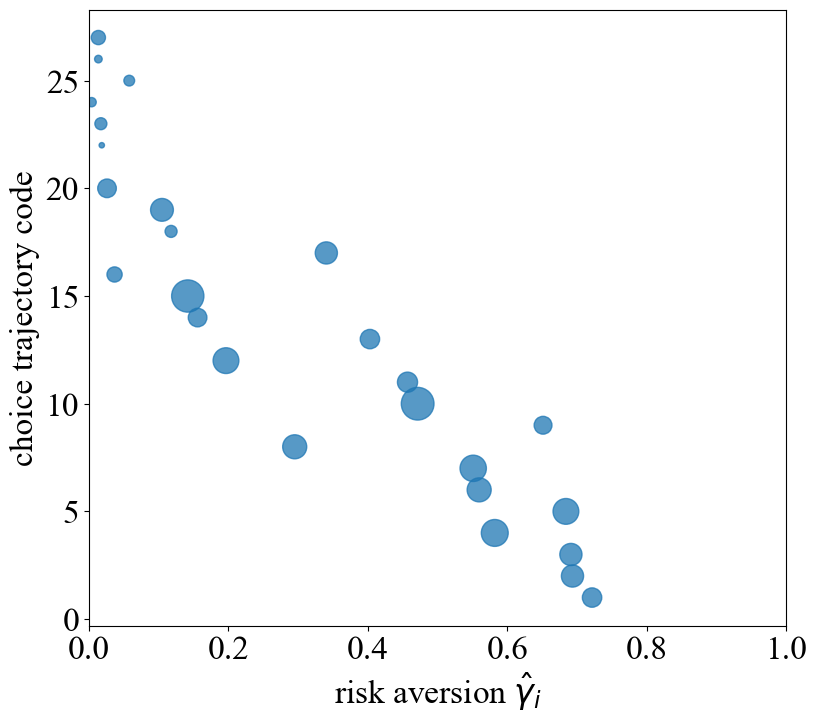

min riskCoef: 0.00385105952085385
max riskCoef: 0.7213743526406907
PearsonRResult(statistic=np.float64(-0.901198005038015), pvalue=np.float64(7.227915220213039e-142))


In [35]:
model = pickle.load(open('models_psm_rpm/risk_class_3.pkl', 'rb'))

if 'path_code' not in df_rpm.columns:
    df_rpm['path_code'] = df_rpm['v_110']

if 'choice_like' not in df_rpm.columns:
    df_rpm['choice_like'] = df_rpm['pid']

plot_coef_code(df_rpm, model)

In [5]:
# Use simulated data to compare RUM vs RPM
# Data generation: representative agent model
x_cols = [col for col in df_risk.columns if 'layer_x' in col]
choice_cols = [col for col in df_risk.columns if 'layer_choice' in col]
bounds = [(0,None),(0,None)]

model = DCM.mixedDiscrete(data=df_risk,
                choice = choice_cols,
                x1 = 300,
                x2 = x_cols,
                p1 = 0.5)

model.set_init_param(param_keys=['riskCoef','temp'],param_init=[0.5,1.0])
model.fit_param(bounds=bounds)
all_args = model.fixed_args | dict(zip(model.param_keys, model.result.x))
df_const_risk_encode = get_model_implied_dist(model,df_risk,all_args).reset_index().rename(
                            columns={'index':'path_code',0:'choice_like'})

# Construct full data table
j_max = 4

for j in range(j_max+1):
    for i in range(2**(j_max-j)):

        col_name = 'layer_' + str(j_max-j+1) + '_q' +str(i+1)

        conditions = [
            df_const_risk_encode['path_code'].between((2*i)*2**j+1, (2*i+1)*2**j),   
            df_const_risk_encode['path_code'].between((2*i+1)*2**j+1, (2*i+2)*2**j) 
        ]

        choice_labels = [0, 1]

        new_col = np.select(conditions, choice_labels, default=np.nan)
        
        df_const_risk_encode = pd.concat([df_const_risk_encode, pd.DataFrame({col_name: new_col})], axis=1)


df_tmp_risk_encode = df_const_risk_encode.melt(id_vars='path_code', value_vars=q_columns, 
                        var_name='q_risk', value_name='choice').dropna()

df_tmp_risk_encode['x'] = df_tmp_risk_encode['q_risk'].apply(sure_pay)*10
df_tmp_risk_encode['layer'] = df_tmp_risk_encode['q_risk'].apply(lambda x: x.strip().split('_')[1])

# Pivot the data
df_tmp_risk_encode = df_tmp_risk_encode.drop_duplicates().pivot(index='path_code', columns='layer', values=['x', 'choice'])

df_tmp_risk_encode.columns = [f"layer_{col}_{layer}" for col, layer in df_tmp_risk_encode.columns]
df_const_risk_encode = df_const_risk_encode[['path_code','choice_like']].join(df_tmp_risk_encode, 
                                                                              on = 'path_code')

# Transform likelihood to choices
df_const_risk_encode['choice_count'] = (df_const_risk_encode['choice_like'].astype(float)*1000).round().astype(int)

df_gen_choices = df_const_risk_encode.loc[
    df_const_risk_encode.index.repeat(df_const_risk_encode['choice_count'])
].reset_index(drop=True)

  message: CONVERGENCE: RELATIVE REDUCTION OF F <= FACTR*EPSMCH
  success: True
   status: 0
      fun: 1299509.7691860634
        x: [ 4.530e-01  5.281e+00]
      nit: 17
      jac: [ 1.630e-01 -2.328e-02]
     nfev: 57
     njev: 19
 hess_inv: <2x2 LbfgsInvHessProduct with dtype=float64>


In [50]:
bounds = [(0,1)]

model = DCM.mixedDiscrete(data=df_gen_choices,
                choice = choice_cols,
                x1 = 300,
                x2 = x_cols,
                p1 = 0.5,
                fixed_args= {'temp':5.2})


model.set_init_param(param_keys=['riskCoef'],param_init=[0.5])
model.fit_param(bounds=bounds)

  message: CONVERGENCE: RELATIVE REDUCTION OF F <= FACTR*EPSMCH
  success: True
   status: 0
      fun: 3244830.089218666
        x: [ 4.503e-01]
      nit: 7
      jac: [-2.794e-01]
     nfev: 18
     njev: 9
 hess_inv: <1x1 LbfgsInvHessProduct with dtype=float64>


In [51]:
DCM.bisection_search(model, bounds, arg_name = 'temp', arg_range = [0.2, 5.2],
                     n_class=2, n_init_point = 8, name_prefix = 'models_psm_rpm/const_gen_rum')

Searching optimal value for temp
Step 1: 1.8666666666666667
Evaluation metrics: 3751.9270148297396, 3897.2426410585167
Step 2: 2.422222222222222
Evaluation metrics: 3910.26082250619, 3653.2736063382345
Step 3: 2.0518518518518514
Evaluation metrics: 3499.268787577772, 3654.868805093039
Step 4: 1.804938271604938
Evaluation metrics: 3382.9520820765324, 3714.8602816453276
Step 5: 1.9695473251028806
Evaluation metrics: 3800.8381274972317, 3735.5195653724095
Step 6: 2.0792866941015085
Evaluation metrics: 3753.472770635686, 3727.853528874682
Step 7: 2.0061271147690896
Evaluation metrics: 3338.606890519857, 3722.1227645480176
Step 8: 2.054900167657369
Evaluation metrics: 3764.388280484942, 3732.8978728689667
Step 9: 2.0223847990651826
Evaluation metrics: 3495.1529881439515, 3738.013335029847
Step 10: 2.000707886670392
Evaluation metrics: 3388.8651237415743, 3530.680377482488


({'temp': 2.000707886670392}, np.float64(3478.8556039729406))

In [52]:
DCM.bisection_search(model, bounds, arg_name = 'temp', arg_range = [0.2, 5.2],
                     n_class=3, n_init_point = 8, name_prefix = 'models_psm_rpm/const_gen_rum')

Searching optimal value for temp
Step 1: 1.8666666666666667
Evaluation metrics: 4239.357519869028, 4307.1454154830235
Step 2: 2.422222222222222
Evaluation metrics: 4126.202550703498, 4087.0856374057
Step 3: 2.7925925925925927
Evaluation metrics: 4210.810511110815, 4155.349337184995
Step 4: 2.545679012345679
Evaluation metrics: 3963.134796965431, 4240.26350844298
Step 5: 2.3810699588477364
Evaluation metrics: 4107.663434560524, 4153.5196571883525
Step 6: 2.4908093278463648
Evaluation metrics: 4118.569545120261, 4073.290706791715
Step 7: 2.417649748513946
Evaluation metrics: 3353.3786281845983, 4080.961896378744
Step 8: 2.466422801402225
Evaluation metrics: 4071.7158171963224, 3996.735314054342
Step 9: 2.4989381699944113
Evaluation metrics: 4121.339439391127, 4105.095458548107
Step 10: 2.5206150823892024
Evaluation metrics: 4126.8667102864165, 4061.8729735799297


({'temp': 2.5206150823892024}, np.float64(4153.961502087202))

In [54]:
DCM.bisection_search(model, bounds, arg_name = 'temp', arg_range = [0.2, 5.2],
                     n_class=4, n_init_point = 8, name_prefix = 'models_psm_rpm/const_gen_rum')

Searching optimal value for temp
Step 1: 3.533333333333333
Evaluation metrics: 4516.515943530653, 3543.0343312369946
Step 2: 2.977777777777778
Evaluation metrics: 3866.6645812812194, 4610.11182739719
Step 3: 3.348148148148148
Evaluation metrics: 4345.806437785109, 3630.8369354462648
Step 4: 3.5950617283950614
Evaluation metrics: 3993.023177819147, 3592.9074077693704
Step 5: 3.4304526748971194
Evaluation metrics: 3355.9354669700424, 3616.1644994371513
Step 6: 3.320713305898491
Evaluation metrics: 3471.539760696817, 3490.89252528974
Step 7: 3.247553726566072
Evaluation metrics: 3545.919892691589, 3885.703969673487
Step 8: 3.2963267794543514
Evaluation metrics: 3872.594801630992, 3726.142366184321
Step 9: 3.263811410862165
Evaluation metrics: 3600.3627208976745, 3618.5397290717965
Step 10: 3.242134498467374
Evaluation metrics: 3723.9811213788385, 3843.8959879955582


({'temp': 3.242134498467374}, np.float64(3844.512028645424))

In [10]:
pid_outlier = df_gen_choices.loc[df_gen_choices[x_cols].ge(300).any(axis=1), 'path_code']
df_gen_rpm = df_gen_choices[~df_gen_choices['path_code'].isin(pid_outlier)]

bounds = [(0,1)]

model = DCM.mixedDiscrete(data=df_gen_rpm,
                choice = choice_cols,
                x1 = 300,
                x2 = x_cols,
                p1 = 0.5,
                fixed_args= {'temp':2.2},
                func = 'rpmLogitProb')


model.set_init_param(param_keys=['riskCoef'],param_init=[0.5])
model.fit_param(bounds=bounds)

  message: CONVERGENCE: RELATIVE REDUCTION OF F <= FACTR*EPSMCH
  success: True
   status: 0
      fun: 3156528.1564020077
        x: [ 1.665e-01]
      nit: 4
      jac: [ 4.657e-02]
     nfev: 10
     njev: 5
 hess_inv: <1x1 LbfgsInvHessProduct with dtype=float64>


In [44]:
DCM.bisection_search(model, bounds, arg_name = 'temp', arg_range = [0.2, 2.2],
                     n_class=2, n_init_point = 8, name_prefix = 'models_psm_rpm/const_gen_rpm')

Searching optimal value for temp
Step 1: 0.8666666666666668
Evaluation metrics: 3818.9093220957243, 3824.084992193359
Step 2: 1.088888888888889
Evaluation metrics: 3862.2511977608983, 3800.596179001948
Step 3: 1.2370370370370374
Evaluation metrics: 3812.605789398274, 3779.0158091598887
Step 4: 1.3358024691358028
Evaluation metrics: 3795.0676009955832, 3753.0883832026148
Step 5: 1.4016460905349797
Evaluation metrics: 3771.669269175375, 3728.8100230576047
Step 6: 1.4455418381344312
Evaluation metrics: 3745.6244698866158, 3712.2502388908706
Step 7: 1.4748056698673986
Evaluation metrics: 3722.744754789811, 3703.76681397743
Step 8: 1.4552964487120867
Evaluation metrics: 3708.6574671869876, 3726.6750109385116
Step 9: 1.4683025961489613
Evaluation metrics: 3712.3386924324677, 3705.9125317221706
Step 10: 1.459631831191045
Evaluation metrics: 3707.403054058016, 3707.512080620491


({'temp': 1.459631831191045}, np.float64(3707.2167048254573))

In [45]:
DCM.bisection_search(model, bounds, arg_name = 'temp', arg_range = [0.2, 2.2],
                     n_class=3, n_init_point = 8, name_prefix = 'models_psm_rpm/const_gen_rpm')

Searching optimal value for temp
Step 1: 0.8666666666666668
Evaluation metrics: 4152.427361338735, 4185.120625884906
Step 2: 0.6444444444444445
Evaluation metrics: 4150.032673102847, 4178.07739212216
Step 3: 0.7925925925925927
Evaluation metrics: 4203.088552090674, 4151.104302754963
Step 4: 0.8913580246913582
Evaluation metrics: 4161.284708360145, 4149.276450766978
Step 5: 0.8255144032921811
Evaluation metrics: 4149.83764127917, 4162.704611635355
Step 6: 0.8694101508916324
Evaluation metrics: 4152.474633680984, 4151.721118026711
Step 7: 0.8401463191586649
Evaluation metrics: 4149.034598089051, 4151.264158816586
Step 8: 0.8206370980033533
Evaluation metrics: 4151.103693821211, 4153.502599413398
Step 9: 0.8336432454402276
Evaluation metrics: 4144.160345630668, 4125.733561319223
Step 10: 0.8423140103981439
Evaluation metrics: 4149.717300181268, 4149.54085538406


({'temp': 0.8423140103981439}, np.float64(4152.89122572112))

In [46]:
DCM.bisection_search(model, bounds, arg_name = 'temp', arg_range = [0.2, 2.2],
                     n_class=4, n_init_point = 8, name_prefix = 'models_psm_rpm/const_gen_rpm')

Searching optimal value for temp
Step 1: 0.8666666666666668
Evaluation metrics: 4349.277093218543, 4493.861146028414
Step 2: 1.088888888888889
Evaluation metrics: 4468.151427533104, 4401.87327057342
Step 3: 0.940740740740741
Evaluation metrics: 4365.094593077109, 4448.154662043235
Step 4: 0.8419753086419756
Evaluation metrics: 4346.373847957924, 4390.278757596789
Step 5: 0.7761316872427986
Evaluation metrics: 4341.2365606071, 4356.783322508692
Step 6: 0.7322359396433473
Evaluation metrics: 4342.333553014167, 4344.930133501306
Step 7: 0.7614997713763147
Evaluation metrics: 4343.3251956463055, 4341.802404565248
Step 8: 0.7810089925316266
Evaluation metrics: 4341.637024638294, 4341.32014197321
Step 9: 0.768002845094752
Evaluation metrics: 4340.321267744515, 4340.446696357353
Step 10: 0.7766736100526683
Evaluation metrics: 4341.829081487402, 4341.270846686066


({'temp': 0.7766736100526683}, np.float64(4339.433037948127))

In [55]:
# Model performance: RUM
model_const = DCM.mixedDiscrete(data=df_gen_choices,
                choice = choice_cols,
                x1 = 300,
                x2 = x_cols,
                p1 = 0.5)

model_const.set_init_param(param_keys=['riskCoef','temp'],param_init=[0.5,1.0])
model_const.fit_param(bounds=bounds,show=False)

pred_const_model_risk = model_const.predict()
pred_const_model_risk['approx_log_like'] = model_const.result.fun / 1000

print('const params:',pred_const_model_risk)

for i in range(2,5):
    model = pickle.load(open(f'models_psm_rpm/const_gen_rum_class_{i}.pkl', 'rb'))
    pred_metric = model.predict()
    pred_metric['approx_log_like'] = model.eval()
    print(f'model {i}:', pred_metric)


const params: {'accuracy': np.float64(0.5987975951903808), 'RMSE': np.float64(0.24050197159846107), 'cross-entropy': np.float64(0.6740210257708197), 'approx_log_like': np.float64(3363.364918596392)}
model 2: {'accuracy': np.float64(0.5987975951903808), 'RMSE': np.float64(0.2339409984525862), 'cross-entropy': np.float64(0.660220021844782), 'approx_log_like': np.float64(3478.8556039729406)}
model 3: {'accuracy': np.float64(0.6414829659318637), 'RMSE': np.float64(0.22483422762219232), 'cross-entropy': np.float64(0.6399868693236894), 'approx_log_like': np.float64(4153.961502087202)}
model 4: {'accuracy': np.float64(0.613627254509018), 'RMSE': np.float64(0.23061259559210473), 'cross-entropy': np.float64(0.6533122532436384), 'approx_log_like': np.float64(3844.512028645424)}


In [47]:
# Model performance: RPM
model_const = DCM.mixedDiscrete(data=df_gen_rpm,
                choice = choice_cols,
                x1 = 300,
                x2 = x_cols,
                p1 = 0.5,
                func = 'rpmLogitProb')

model_const.set_init_param(param_keys=['riskCoef','temp'],param_init=[0.5,1.0])
model_const.fit_param(bounds=bounds,show=False)

pred_const_model_risk = model_const.predict()
pred_const_model_risk['approx_log_like'] = model_const.result.fun / 1000

print('const params:',pred_const_model_risk)

for i in range(2,5):
    model = pickle.load(open(f'models_psm_rpm/const_gen_rpm_class_{i}.pkl', 'rb'))
    pred_metric = model.predict()
    pred_metric['approx_log_like'] = model.eval()
    print(f'model {i}:', pred_metric)


const params: {'accuracy': np.float64(0.6206967213114754), 'RMSE': np.float64(0.22952926710913224), 'cross-entropy': np.float64(0.6633204713431986), 'approx_log_like': np.float64(3237.00390015481)}
model 2: {'accuracy': np.float64(0.6532786885245903), 'RMSE': np.float64(0.22271765244114475), 'cross-entropy': np.float64(0.637353345661082), 'approx_log_like': np.float64(3707.2167048254573)}
model 3: {'accuracy': np.float64(0.7336065573770492), 'RMSE': np.float64(0.21089011421260673), 'cross-entropy': np.float64(0.6256419535979298), 'approx_log_like': np.float64(4152.89122572112)}
model 4: {'accuracy': np.float64(0.7301229508196722), 'RMSE': np.float64(0.20910351591548268), 'cross-entropy': np.float64(0.6257682212421245), 'approx_log_like': np.float64(4339.433037948127)}


min riskCoef: 0.023192929929618633
max riskCoef: 0.7623131656258288
PearsonRResult(statistic=np.float64(-0.8655638359935209), pvalue=np.float64(8.749300502828693e-295))


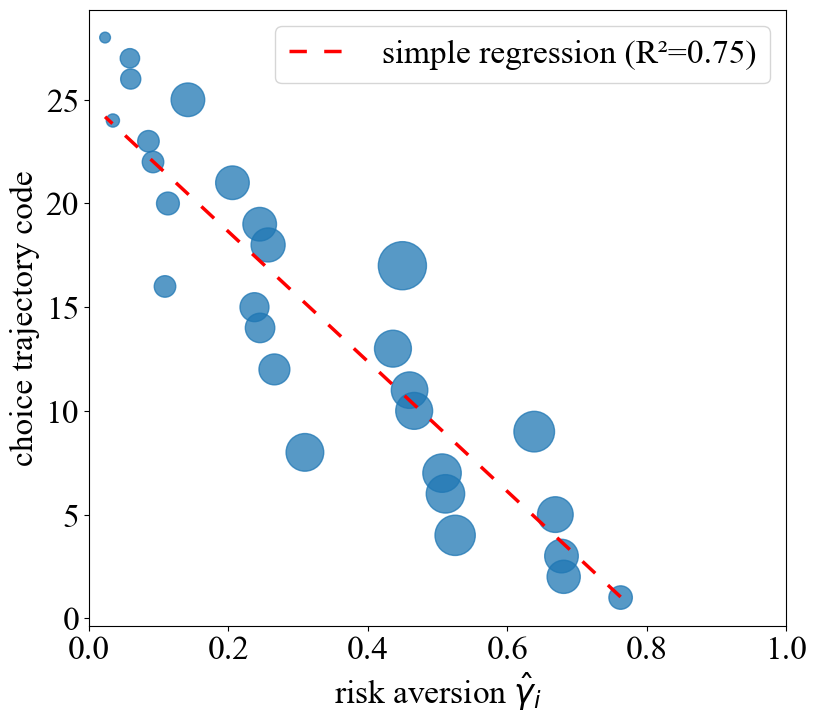

In [162]:
model = pickle.load(open('models_psm_rpm/const_gen_rpm_class_3.pkl', 'rb'))
plot_coef_code(df_gen_rpm, model, show = False)

slope, intercept, r, p_value, std_err = st.linregress(x=df_gen_rpm['riskCoef'], y=df_gen_rpm['path_code'])
pred_subgroup = slope * df_gen_rpm['riskCoef'] + intercept
plt.plot(df_gen_rpm['riskCoef'], pred_subgroup, color='red', linestyle=(0,(5,5)), linewidth = 2.5, 
         label= f"simple regression (R²={r**2:.2f})")

plt.legend(loc='best')
plt.show()

min riskCoef: 0.675458944919919
max riskCoef: 0.8651053682927228
PearsonRResult(statistic=np.float64(0.6385311926384075), pvalue=np.float64(2.0635173836024066e-115))


<Figure size 900x800 with 0 Axes>

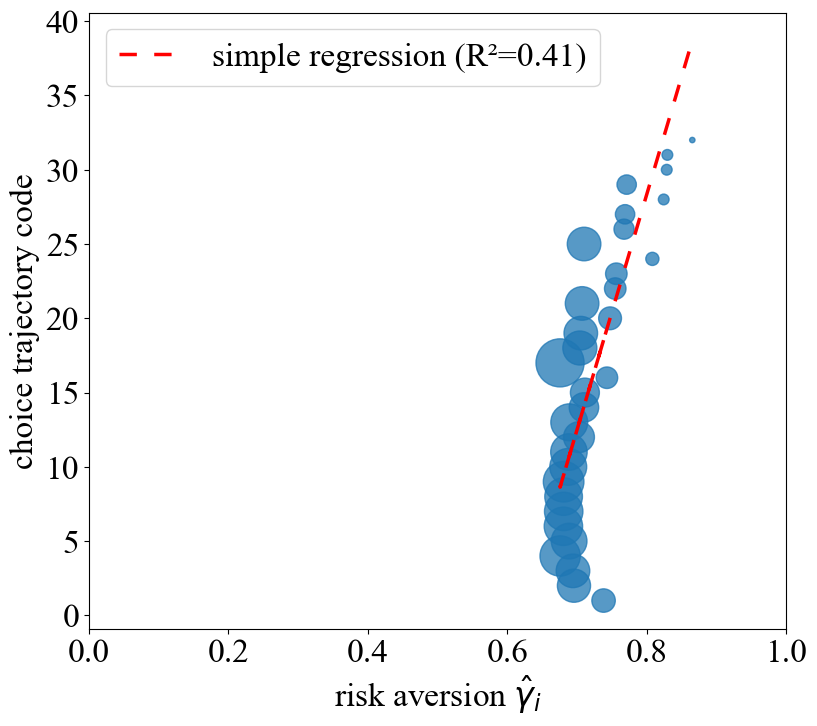

In [164]:
plt.rcParams['font.family'] = 'Times New Roman'
plt.rcParams['font.size'] = 24
plt.figure(figsize=(9, 8))

model = pickle.load(open('models_psm_rpm/const_gen_rum_class_3.pkl', 'rb'))
plot_coef_code(df_gen_choices, model, show = False)

slope, intercept, r, p_value, std_err = st.linregress(x=df_gen_choices['riskCoef'], y=df_gen_choices['path_code'])
pred_subgroup = slope * df_gen_choices['riskCoef'] + intercept
plt.plot(df_gen_choices['riskCoef'], pred_subgroup, color='red', linestyle=(0,(5,5)), linewidth = 2.5, 
         label= f"simple regression (R²={r**2:.2f})")

plt.legend(loc='best')
plt.show()

In [7]:
df_diverse_risk = df_const_risk_encode[['path_code'] + x_cols + choice_cols] 

model_diverse = DCM.mixedDiscrete(data=df_diverse_risk,
                choice = choice_cols,
                x1 = 300,
                x2 = x_cols,
                p1 = 0.5)

def generate_choices_from_prob(df, base_count=500):
    """
    simulate choices based on computed choice probabilities
    """

    # Define column names
    layer_choices = [f'layer_choice_{i}' for i in range(1, 6)]
    layer_likes   = [f'layer_like_{i}' for i in range(1, 6)]

    # Compute conditional probability for each layer based on the actual choice
    for c, l in zip(layer_choices, layer_likes):
        df[f'_tmp_{l}'] = (
            df[c] * df[l] + (1 - df[c]) * (1 - df[l])
        )

    # Multiply all layer probabilities to obtain the final compounded probability
    tmp_cols = [f'_tmp_{l}' for l in layer_likes]
    df['choice_like'] = df[tmp_cols].prod(axis=1)

    # Convert probability into count
    df['choice_count'] = (df['choice_like'] * base_count).round().astype(int)

    # Replicate rows according to choice_count
    df_expanded = df.loc[df.index.repeat(df['choice_count'])].reset_index(drop=True)

    return df_expanded


# create datasets
def generate_multiagent_data(df, model, risk_coefs, base_count=500):

    dfs = pd.DataFrame()
    
    for risk_coef in risk_coefs:
        df[[f'layer_like_{i}' for i in range(1, 6)]] = model.choiceProb(
            params={'riskCoef': risk_coef, 'temp': 1, 'delta': 1})
        
        _tmp = generate_choices_from_prob(df, base_count)
        dfs = pd.concat([dfs, _tmp], axis=0, ignore_index=True)
    

    # Select only the required columns
    result_df = dfs[x_cols + choice_cols + ['path_code', 'choice_like']]
    
    return result_df

df_diverse_2type = generate_multiagent_data(df_diverse_risk, 
                                           model_diverse, 
                                           risk_coefs=[0.1,0.9], 
                                           base_count=500)

df_diverse_3type = generate_multiagent_data(df_diverse_risk, 
                                           model_diverse, 
                                           risk_coefs=[0.1,0.5,0.9], 
                                           base_count=500)


pid_outlier = df_diverse_2type.loc[df_diverse_2type[x_cols].ge(300).any(axis=1), :].index
df_diverse_2type_edited = df_diverse_2type[~df_diverse_2type.index.isin(pid_outlier)]
print('outliers removed for two-type sample:',len(df_diverse_2type) - len(df_diverse_2type_edited))

pid_outlier = df_diverse_3type.loc[df_diverse_3type[x_cols].ge(300).any(axis=1), :].index
df_diverse_3type_edited = df_diverse_3type[~df_diverse_3type.index.isin(pid_outlier)]
print('outliers removed for three-type sample:',len(df_diverse_3type) - len(df_diverse_3type_edited))

outliers removed for two-type sample: 14
outliers removed for three-type sample: 14


In [128]:
tab_count = df_diverse_3type_edited['path_code'].value_counts()
tab_count.index = tab_count.index.astype(int).astype(str)

prop_test = DCM.proportionTest(tab_count)
prop_test.run(hide=True)
prop_test.get_power(method='fisher')
prop_test.get_power(method='barnard')

print('Fisher p-value:',prop_test.get_overall_pvalue(method='fisher')) 
print('Barnard p-value:',prop_test.get_overall_pvalue(method='barnard')) 

Fisher p-value: 0.011235904505576842
Barnard p-value: 0.0169879867711653


In [78]:
bounds = [(0,None),(0,None)]

model = DCM.mixedDiscrete(data=df_diverse_2type_edited,
                choice = choice_cols,
                x1 = 300,
                x2 = x_cols,
                p1 = 0.5)

model.set_init_param(param_keys=['riskCoef','temp'],param_init=[0.5,1.0])
model.fit_param(bounds=bounds)
pred_const_model_risk = model.predict()
pred_const_model_risk['approx_log_like'] = model.result.fun / 1000

  message: CONVERGENCE: RELATIVE REDUCTION OF F <= FACTR*EPSMCH
  success: True
   status: 0
      fun: 3293455.3053414454
        x: [ 6.856e-01  1.993e+01]
      nit: 22
      jac: [ 3.511e+01 -4.657e-02]
     nfev: 90
     njev: 30
 hess_inv: <2x2 LbfgsInvHessProduct with dtype=float64>


In [81]:
bounds = [(0,1)]

model = DCM.mixedDiscrete(data=df_diverse_2type_edited,
                choice = choice_cols,
                x1 = 300,
                x2 = x_cols,
                p1 = 0.5,
                fixed_args= {'temp':19})


model.set_init_param(param_keys=['riskCoef'],param_init=[0.5])
model.fit_param(bounds=bounds)

  message: CONVERGENCE: RELATIVE REDUCTION OF F <= FACTR*EPSMCH
  success: True
   status: 0
      fun: 3293498.6007126644
        x: [ 6.785e-01]
      nit: 6
      jac: [ 2.794e-01]
     nfev: 22
     njev: 11
 hess_inv: <1x1 LbfgsInvHessProduct with dtype=float64>


In [82]:
DCM.bisection_search(model, bounds, arg_name = 'temp', arg_range = [0.2, 19],
                     n_class=2, n_init_point = 8, name_prefix = 'models_psm_rpm/diverse_gen_rum')

Searching optimal value for temp
Step 1: 6.466666666666667
Evaluation metrics: 2938.685018698655, 3189.1770905564763
Step 2: 4.377777777777778
Evaluation metrics: 2800.0098872282183, 3045.4140241389496
Step 3: 5.7703703703703715
Evaluation metrics: 3808.9959793532744, 2896.057551959616
Step 4: 4.841975308641977
Evaluation metrics: 2833.608021155772, 2952.079481978653
Step 5: 4.223045267489713
Evaluation metrics: 2788.4350850136652, 2875.9428679033686
Step 6: 4.635665294924555
Evaluation metrics: 3461.972377120289, 2818.875978168883
Step 7: 4.3605852766346604
Evaluation metrics: 2798.733600020517, 2838.4226575977073
Step 8: 4.177198597774731
Evaluation metrics: 2784.9662213160764, 2812.2269247410723
Step 9: 4.054940811868111
Evaluation metrics: 2775.6247405618224, 2794.1761379174172
Step 10: 3.9734356212636976
Evaluation metrics: 2769.3188712072406, 2781.867701191416


({'temp': 3.9734356212636976}, np.float64(2769.318891426665))

In [83]:
DCM.bisection_search(model, bounds, arg_name = 'temp', arg_range = [0.2, 19],
                     n_class=3, n_init_point = 8, name_prefix = 'models_psm_rpm/diverse_gen_rum')

Searching optimal value for temp
Step 1: 6.466666666666667
Evaluation metrics: 3101.917696324561, 3436.012238798273
Step 2: 4.377777777777778
Evaluation metrics: 3034.1269516526263, 3141.754938543813
Step 3: 5.7703703703703715
Evaluation metrics: 3495.267411633879, 3113.7448832013924
Step 4: 4.841975308641977
Evaluation metrics: 3002.0715048244147, 3246.3290590060715
Step 5: 4.223045267489713
Evaluation metrics: 2981.6786636073025, 3146.9134665009024
Step 6: 4.635665294924555
Evaluation metrics: 3248.02286196591, 2912.055540485741
Step 7: 4.3605852766346604
Evaluation metrics: 3082.100281967145, 3148.5463330579705
Step 8: 4.543971955494591
Evaluation metrics: 3062.5705839011034, 2989.050284262584
Step 9: 4.66622974140121
Evaluation metrics: 3051.3483569854334, 3038.918304793772
Step 10: 4.747734932005624
Evaluation metrics: 3106.4456516412524, 2889.0575687161336


({'temp': 4.747734932005624}, np.float64(3064.9827221398386))

In [84]:
print('const params:',pred_const_model_risk)

for i in range(2,4):
    model = pickle.load(open(f'models_psm_rpm/diverse_gen_rum_class_{i}.pkl', 'rb'))
    pred_metric = model.predict()
    pred_metric['approx_log_like'] = model.eval()
    print(f'model {i}:', pred_metric)

const params: {'accuracy': np.float64(0.5727087576374746), 'RMSE': np.float64(0.23865650381478554), 'cross-entropy': np.float64(0.670764827971781), 'approx_log_like': np.float64(3293.455305341445)}
model 2: {'accuracy': np.float64(0.7802443991853361), 'RMSE': np.float64(0.13539985462051227), 'cross-entropy': np.float64(0.4132230125311481), 'approx_log_like': np.float64(2769.318891426665)}
model 3: {'accuracy': np.float64(0.7684317718940937), 'RMSE': np.float64(0.139003701460736), 'cross-entropy': np.float64(0.4252985837974049), 'approx_log_like': np.float64(3064.9827221398386)}


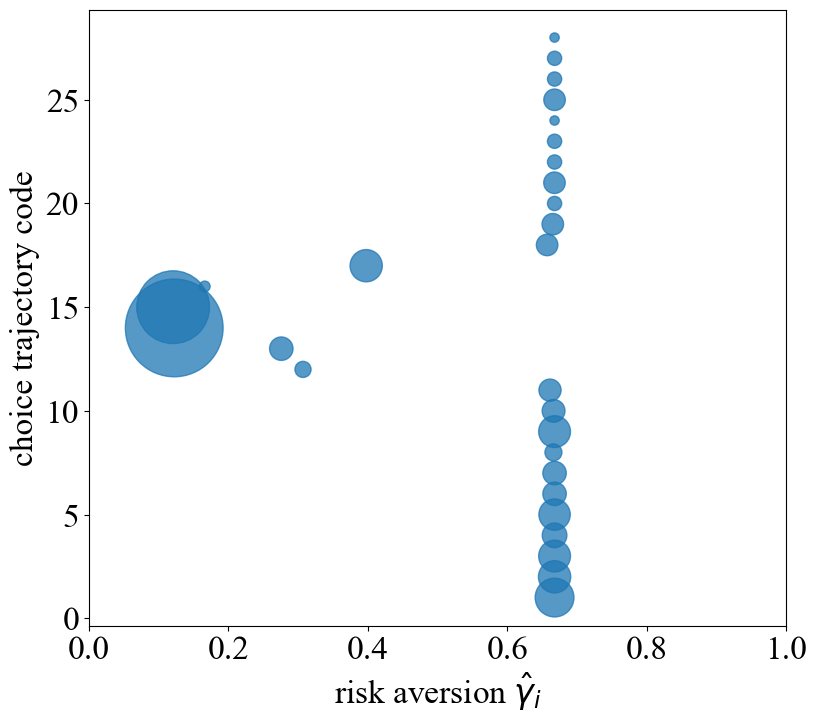

min riskCoef: 0.12075489700862285
max riskCoef: 0.6676250184541808
PearsonRResult(statistic=np.float64(-0.402938524626565), pvalue=np.float64(1.250240190858145e-39))


In [297]:
model = pickle.load(open('models_psm_rpm/diverse_gen_rum_class_2.pkl', 'rb'))
plot_coef_code(df_diverse_2type_edited, model)

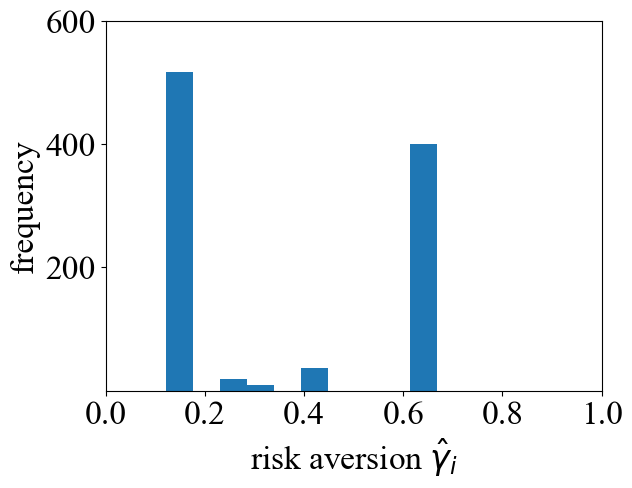

In [298]:
plt.hist(df_diverse_2type_edited['riskCoef'])
plt.ylabel('frequency')
plt.xlabel(r'risk aversion $\hat{\gamma}_i$')
plt.xticks(np.arange(0,1.1,0.2))
plt.yticks([200,400,600])
plt.show()

In [95]:
model = DCM.mixedDiscrete(data=df_diverse_2type_edited,
                choice = choice_cols,
                x1 = 300,
                x2 = x_cols,
                p1 = 0.5,
                func='rpmLogitProb')

model.set_init_param(param_keys=['riskCoef','temp'],param_init=[0.5,0.5])
model.fit_param(bounds=bounds)
pred_const_model_risk = model.predict()
pred_const_model_risk['approx_log_like'] = model.result.fun / 1000

  message: CONVERGENCE: RELATIVE REDUCTION OF F <= FACTR*EPSMCH
  success: True
   status: 0
      fun: 3277937.4294820223
        x: [ 7.420e-01  1.000e+00]
      nit: 5
      jac: [-5.122e-01 -6.353e+04]
     nfev: 21
     njev: 7
 hess_inv: <2x2 LbfgsInvHessProduct with dtype=float64>


In [96]:
bounds = [(0,1)]

model = DCM.mixedDiscrete(data=df_diverse_2type_edited,
                choice = choice_cols,
                x1 = 300,
                x2 = x_cols,
                p1 = 0.5,
                fixed_args= {'temp':1.0},
                func = 'rpmLogitProb')


model.set_init_param(param_keys=['riskCoef'],param_init=[0.7])
model.fit_param(bounds=bounds)

  message: CONVERGENCE: RELATIVE REDUCTION OF F <= FACTR*EPSMCH
  success: True
   status: 0
      fun: 3277937.429481959
        x: [ 7.420e-01]
      nit: 2
      jac: [-3.725e-01]
     nfev: 8
     njev: 4
 hess_inv: <1x1 LbfgsInvHessProduct with dtype=float64>


In [97]:
DCM.bisection_search(model, bounds, arg_name = 'temp', arg_range = [0.2, 1.0],
                     n_class=2, n_init_point = 8, name_prefix = 'models_psm_rpm/diverse_gen_rpm')

Searching optimal value for temp
Step 1: 0.4666666666666667
Evaluation metrics: 3477.1537510825465, 3598.2523823357037
Step 2: 0.37777777777777777
Evaluation metrics: 3451.438085583368, 3518.362402540138
Step 3: 0.31851851851851853
Evaluation metrics: 3462.388829232866, 3465.6060800954974
Step 4: 0.3580246913580247
Evaluation metrics: 3497.369684454431, 3451.1039957064704
Step 5: 0.3843621399176955
Evaluation metrics: 3456.034937486169, 3452.153730722825
Step 6: 0.36680384087791496
Evaluation metrics: 3450.890693904654, 3455.2790158399657
Step 7: 0.355098308184728
Evaluation metrics: 3451.3167356616464, 3451.5039961812836
Step 8: 0.36290199664685263
Evaluation metrics: 3452.260116548949, 3450.909400235493
Step 9: 0.36810445562160243
Evaluation metrics: 3451.124007699739, 3450.9103668282296
Step 10: 0.3646361496384359
Evaluation metrics: 3450.8864726737693, 3451.023853410167


({'temp': 0.3646361496384359}, np.float64(3450.886476722084))

In [98]:
DCM.bisection_search(model, bounds, arg_name = 'temp', arg_range = [0.2, 1.0],
                     n_class=3, n_init_point = 8, name_prefix = 'models_psm_rpm/diverse_gen_rpm')

Searching optimal value for temp
Step 1: 0.4666666666666667
Evaluation metrics: 3983.6408746941484, 4116.062187703751
Step 2: 0.37777777777777777
Evaluation metrics: 3954.8587608098683, 3976.0479041873423
Step 3: 0.31851851851851853
Evaluation metrics: 3924.755410325235, 3958.569030402801
Step 4: 0.27901234567901234
Evaluation metrics: 3843.4709396312082, 3959.1442034968045
Step 5: 0.25267489711934155
Evaluation metrics: 3682.572188060914, 3950.990629798302
Step 6: 0.2702331961591221
Evaluation metrics: 3885.027274989018, 3527.8995086100404
Step 7: 0.2819387288523091
Evaluation metrics: 3830.3228886513407, 3810.428827923892
Step 8: 0.2897424173144338
Evaluation metrics: 3949.4087310221366, 3600.9550998501263
Step 9: 0.28453995833968404
Evaluation metrics: 3872.8633079115352, 3892.1907749703223
Step 10: 0.28800826432285054
Evaluation metrics: 4003.014452413184, 3904.5528379104603


({'temp': 0.28800826432285054}, np.float64(3886.676333968009))

In [100]:
print('const params:',pred_const_model_risk)

for i in range(2,4):
    model = pickle.load(open(f'models_psm_rpm/diverse_gen_rpm_class_{i}.pkl', 'rb'))
    pred_metric = model.predict()
    pred_metric['approx_log_like'] = model.eval()
    print(f'model {i}:', pred_metric)

const params: {'accuracy': np.float64(0.5710794297352343), 'RMSE': np.float64(0.23408114903929284), 'cross-entropy': np.float64(0.6676043644566237), 'approx_log_like': np.float64(3277.9374294820223)}
model 2: {'accuracy': np.float64(0.7981670061099797), 'RMSE': np.float64(0.16975788492105354), 'cross-entropy': np.float64(0.5729412023933598), 'approx_log_like': np.float64(3450.886476722084)}
model 3: {'accuracy': np.float64(0.8059063136456213), 'RMSE': np.float64(0.16235706150670176), 'cross-entropy': np.float64(0.5782635807900796), 'approx_log_like': np.float64(3886.676333968009)}


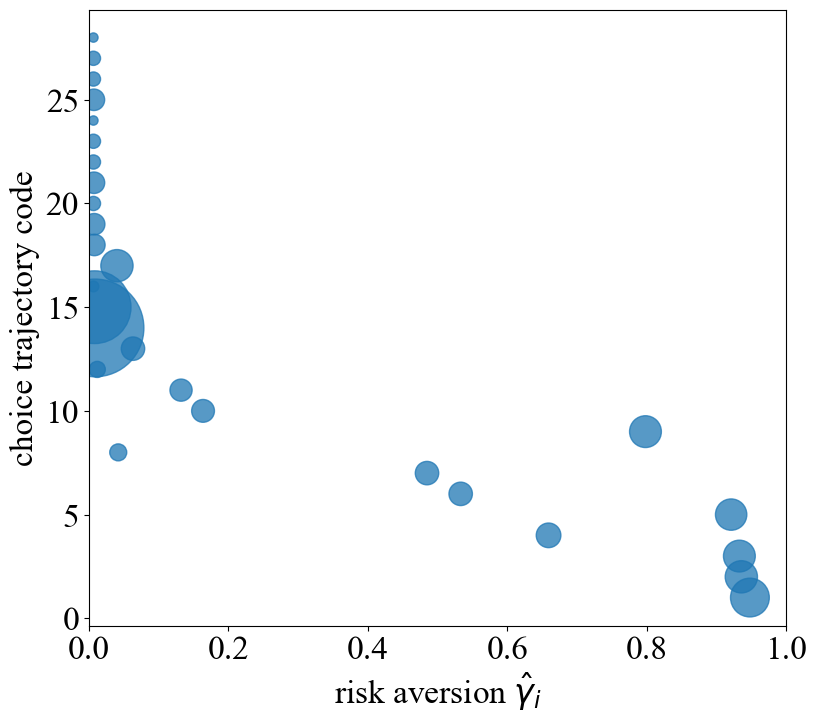

min riskCoef: 0.0064741758017116124
max riskCoef: 0.9476942426114514
PearsonRResult(statistic=np.float64(-0.8589289494323511), pvalue=np.float64(4.31957200551739e-287))


In [299]:
model = pickle.load(open('models_psm_rpm/diverse_gen_rpm_class_3.pkl', 'rb'))
plot_coef_code(df_diverse_2type_edited, model)

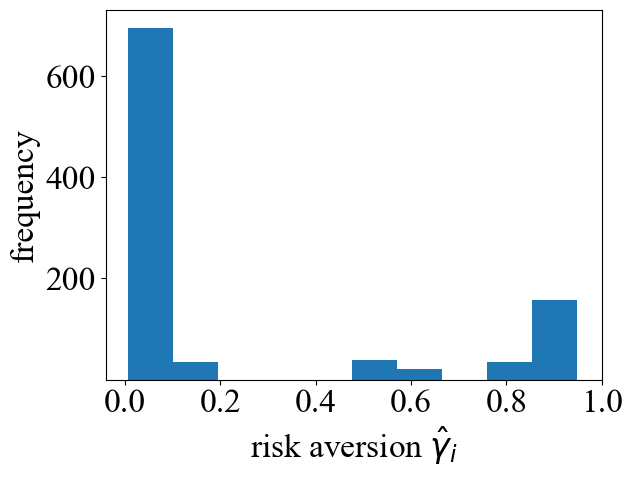

In [300]:
plt.hist(df_diverse_2type_edited['riskCoef'])
plt.ylabel('frequency')
plt.xlabel(r'risk aversion $\hat{\gamma}_i$')
plt.xticks(np.arange(0,1.1,0.2))
plt.yticks([200,400,600])
plt.show()

In [129]:
bounds = [(0,None),(0,None)]

model = DCM.mixedDiscrete(data=df_diverse_3type_edited,
                choice = choice_cols,
                x1 = 300,
                x2 = x_cols,
                p1 = 0.5)

model.set_init_param(param_keys=['riskCoef','temp'],param_init=[0.5,1.0])
model.fit_param(bounds=bounds)
pred_const_model_risk = model.predict()
pred_const_model_risk['approx_log_like'] = model.result.fun / 1000

  message: CONVERGENCE: RELATIVE REDUCTION OF F <= FACTR*EPSMCH
  success: True
   status: 0
      fun: 4763656.236842167
        x: [ 5.759e-01  6.671e+00]
      nit: 15
      jac: [ 3.725e-01 -8.382e-01]
     nfev: 48
     njev: 16
 hess_inv: <2x2 LbfgsInvHessProduct with dtype=float64>


In [132]:
bounds = [(0,1)]

model = DCM.mixedDiscrete(data=df_diverse_3type_edited,
                choice = choice_cols,
                x1 = 300,
                x2 = x_cols,
                p1 = 0.5,
                fixed_args= {'temp':6.6})


model.set_init_param(param_keys=['riskCoef'],param_init=[0.5])
model.fit_param(bounds=bounds)

  message: CONVERGENCE: RELATIVE REDUCTION OF F <= FACTR*EPSMCH
  success: True
   status: 0
      fun: 4763667.696625163
        x: [ 5.745e-01]
      nit: 6
      jac: [-2.235e+00]
     nfev: 16
     njev: 8
 hess_inv: <1x1 LbfgsInvHessProduct with dtype=float64>


In [133]:
DCM.bisection_search(model, bounds, arg_name = 'temp', arg_range = [0.2, 6.6],
                     n_class=2, n_init_point = 8, name_prefix = 'models_psm_rpm/diverse_gen_3type_rum')

Searching optimal value for temp
Step 1: 4.466666666666667
Evaluation metrics: 5679.240129523172, 4638.7469146262265
Step 2: 5.177777777777777
Evaluation metrics: 5298.680986107972, 4710.747719244322
Step 3: 4.703703703703704
Evaluation metrics: 4663.622063437938, 4754.548223051801
Step 4: 4.387654320987654
Evaluation metrics: 4630.255831390366, 4695.419681029307
Step 5: 4.176954732510287
Evaluation metrics: 4607.12188890142, 4652.676624693348
Step 6: 4.036488340192044
Evaluation metrics: 4591.302892378969, 4622.623944050713
Step 7: 3.9428440786465475
Evaluation metrics: 4580.582489619148, 4601.883984638945
Step 8: 3.8804145709495503
Evaluation metrics: 4573.35911763023, 4587.744815550161
Step 9: 3.8387948991515524
Evaluation metrics: 4568.507705793703, 4578.178866717415
Step 10: 3.81104845128622
Evaluation metrics: 4565.262609802144, 4571.7457204759885


({'temp': 3.81104845128622}, np.float64(4565.262555854927))

In [134]:
DCM.bisection_search(model, bounds, arg_name = 'temp', arg_range = [0.2, 6.6],
                     n_class=3, n_init_point = 8, name_prefix = 'models_psm_rpm/diverse_gen_3type_rum')

Searching optimal value for temp
Step 1: 2.3333333333333335
Evaluation metrics: 5207.891790539008, 5265.156621658867
Step 2: 3.0444444444444443
Evaluation metrics: 6108.838931101759, 5602.521664364584
Step 3: 3.5185185185185186
Evaluation metrics: 5658.478533791983, 5526.023624430888
Step 4: 3.8345679012345677
Evaluation metrics: 5572.001684453569, 5169.059481657314
Step 5: 4.045267489711934
Evaluation metrics: 5506.168275690227, 5202.24162568041
Step 6: 3.9048010973936904
Evaluation metrics: 5180.529426360469, 5224.387321543447
Step 7: 3.8111568358481938
Evaluation metrics: 5164.5003843936065, 5195.250271181258
Step 8: 3.8735863435451914
Evaluation metrics: 5501.840158021336, 5175.4806716967705
Step 9: 3.8319666717471934
Evaluation metrics: 5168.373355508051, 5181.567822759451
Step 10: 3.8597131196125254
Evaluation metrics: 5498.25163270514, 5172.651570068873


({'temp': 3.8597131196125254}, np.float64(5173.397504782669))

In [135]:
DCM.bisection_search(model, bounds, arg_name = 'temp', arg_range = [0.2, 6.6],
                     n_class=4, n_init_point = 8, name_prefix = 'models_psm_rpm/diverse_gen_3type_rum')

Searching optimal value for temp
Step 1: 2.3333333333333335
Evaluation metrics: 5055.129645260638, 5615.048682900329
Step 2: 3.0444444444444443
Evaluation metrics: 6492.4565743633975, 5607.995775520171
Step 3: 3.5185185185185186
Evaluation metrics: 5658.730917639065, 5535.451059002726
Step 4: 3.8345679012345677
Evaluation metrics: 5585.553966966893, 5516.291010129724
Step 5: 3.6238683127572013
Evaluation metrics: 5529.606960572968, 5549.822393297994
Step 6: 3.4834019204389577
Evaluation metrics: 5553.164042932402, 5749.451885992565
Step 7: 3.5770461819844535
Evaluation metrics: 5634.581099425235, 5555.26772082899
Step 8: 3.639475689681451
Evaluation metrics: 5576.124959576431, 5531.082437004084
Step 9: 3.681095361479449
Evaluation metrics: 5544.412775203561, 5524.651704595956
Step 10: 3.7088418093447815
Evaluation metrics: 5775.962136872501, 5573.261346014172


({'temp': 3.7088418093447815}, np.float64(5547.068161937385))

In [136]:
print('const params:',pred_const_model_risk)

for i in range(2,5):
    model = pickle.load(open(f'models_psm_rpm/diverse_gen_3type_rum_class_{i}.pkl', 'rb'))
    pred_metric = model.predict()
    pred_metric['approx_log_like'] = model.eval()
    print(f'model {i}:', pred_metric)

const params: {'accuracy': np.float64(0.6326806212018906), 'RMSE': np.float64(0.22556876508348372), 'cross-entropy': np.float64(0.6433026653399279), 'approx_log_like': np.float64(4763.656236842166)}
model 2: {'accuracy': np.float64(0.7912221471978391), 'RMSE': np.float64(0.1569856054807071), 'cross-entropy': np.float64(0.4778845160354904), 'approx_log_like': np.float64(4565.262555854927)}
model 3: {'accuracy': np.float64(0.788791357191087), 'RMSE': np.float64(0.14835872115919763), 'cross-entropy': np.float64(0.45876426159596967), 'approx_log_like': np.float64(5173.397504782669)}
model 4: {'accuracy': np.float64(0.5997299122214719), 'RMSE': np.float64(0.2174327524974341), 'cross-entropy': np.float64(0.6223449926748282), 'approx_log_like': np.float64(5547.068161937385)}


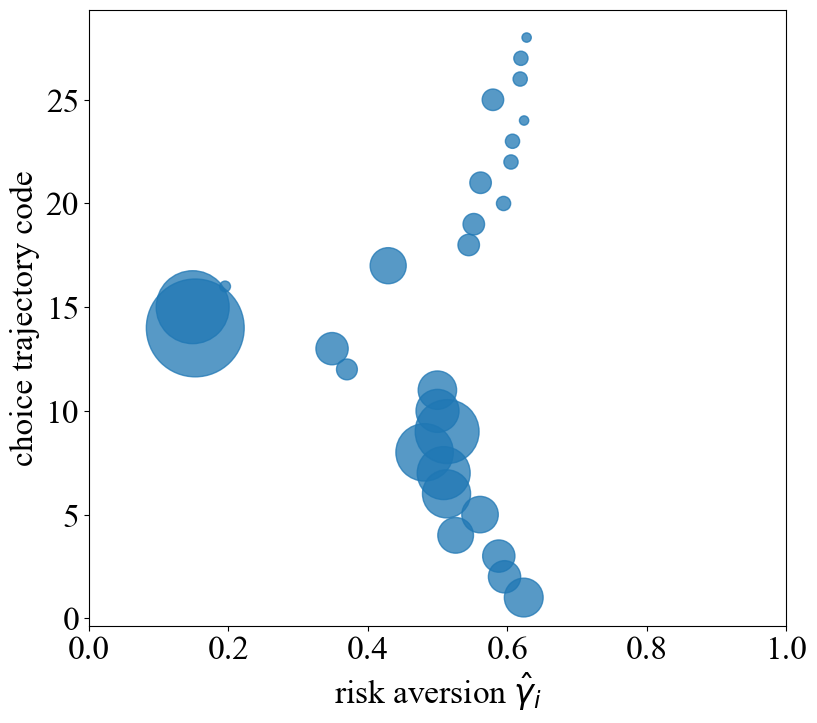

min riskCoef: 0.1487794820948397
max riskCoef: 0.6275704661519865
PearsonRResult(statistic=np.float64(-0.48656535097384473), pvalue=np.float64(7.28885612618057e-89))


In [289]:
model = pickle.load(open('models_psm_rpm/diverse_gen_3type_rum_class_3.pkl', 'rb'))
plot_coef_code(df_diverse_3type_edited, model)

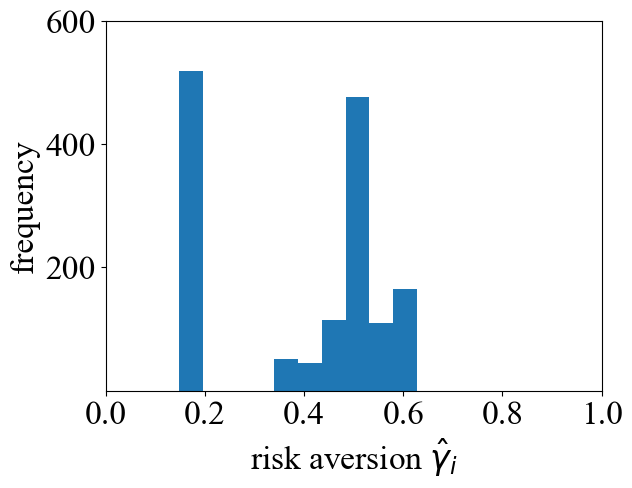

In [290]:
plt.hist(df_diverse_3type_edited['riskCoef'])
plt.ylabel('frequency')
plt.xlabel(r'risk aversion $\hat{\gamma}_i$')
plt.xticks(np.arange(0,1.1,0.2))
plt.yticks([200,400,600])
plt.show()

In [146]:
bounds = [(0,None),(0,None)]

model = DCM.mixedDiscrete(data=df_diverse_3type_edited,
                choice = choice_cols,
                x1 = 300,
                x2 = x_cols,
                p1 = 0.5,
                func = 'rpmLogitProb')

model.set_init_param(param_keys=['riskCoef','temp'],param_init=[0.5,1.0])
model.fit_param(bounds=bounds)
pred_const_model_risk = model.predict()
pred_const_model_risk['approx_log_like'] = model.result.fun / 1000

  message: CONVERGENCE: RELATIVE REDUCTION OF F <= FACTR*EPSMCH
  success: True
   status: 0
      fun: 4828249.760724347
        x: [ 5.907e-01  8.326e-01]
      nit: 8
      jac: [ 4.936e+00 -1.211e+00]
     nfev: 33
     njev: 11
 hess_inv: <2x2 LbfgsInvHessProduct with dtype=float64>


In [147]:
bounds = [(0,1)]

model = DCM.mixedDiscrete(data=df_diverse_3type_edited,
                choice = choice_cols,
                x1 = 300,
                x2 = x_cols,
                p1 = 0.5,
                fixed_args= {'temp':0.8},
                func = 'rpmLogitProb')


model.set_init_param(param_keys=['riskCoef'],param_init=[0.5])
model.fit_param(bounds=bounds)

  message: CONVERGENCE: RELATIVE REDUCTION OF F <= FACTR*EPSMCH
  success: True
   status: 0
      fun: 4828503.967874119
        x: [ 5.967e-01]
      nit: 3
      jac: [-3.725e-01]
     nfev: 10
     njev: 5
 hess_inv: <1x1 LbfgsInvHessProduct with dtype=float64>


In [148]:
DCM.bisection_search(model, bounds, arg_name = 'temp', arg_range = [0.2, 0.8],
                     n_class=2, n_init_point = 8, name_prefix = 'models_psm_rpm/diverse_gen_3type_rpm')

Searching optimal value for temp
Step 1: 0.6000000000000001
Evaluation metrics: 5418.683210674171, 5346.8679404168215
Step 2: 0.5333333333333334
Evaluation metrics: 5323.872097477497, 5361.55376884963
Step 3: 0.48888888888888893
Evaluation metrics: 5319.281812319994, 5339.875030053659
Step 4: 0.5185185185185186
Evaluation metrics: 5359.415263447809, 5318.189828017514
Step 5: 0.49876543209876545
Evaluation metrics: 5310.570316005254, 5325.742071285687
Step 6: 0.5119341563786008
Evaluation metrics: 5323.998514397399, 5315.6468318102325
Step 7: 0.5031550068587106
Evaluation metrics: 5312.257287957125, 5319.035834714103
Step 8: 0.49730224051211713
Evaluation metrics: 5310.009726100986, 5314.5158424424535
Step 9: 0.5012040847431796
Evaluation metrics: 5312.744489435141, 5311.5073902865115
Step 10: 0.4986028552558046
Evaluation metrics: 5310.508010484126, 5312.50891936984


({'temp': 0.4986028552558046}, np.float64(5310.508549061053))

In [149]:
DCM.bisection_search(model, bounds, arg_name = 'temp', arg_range = [0.2, 0.8],
                     n_class=3, n_init_point = 8, name_prefix = 'models_psm_rpm/diverse_gen_3type_rpm')

Searching optimal value for temp
Step 1: 0.4
Evaluation metrics: 6118.587188304788, 6186.583992476016
Step 2: 0.33333333333333337
Evaluation metrics: 6028.414141287062, 6050.859321170829
Step 3: 0.28888888888888886
Evaluation metrics: 5819.902726926961, 6034.605084723601
Step 4: 0.2592592592592593
Evaluation metrics: 5758.762871764676, 5823.900845775174
Step 5: 0.23950617283950618
Evaluation metrics: 5656.712015171407, 5856.3423306304785
Step 6: 0.22633744855967078
Evaluation metrics: 5655.716944170158, 5864.555488732478
Step 7: 0.21755829903978052
Evaluation metrics: 5656.323913958514, 6032.844829956293
Step 8: 0.223411065386374
Evaluation metrics: 5657.515859680045, 5655.783794790084
Step 9: 0.22731290961743636
Evaluation metrics: 5925.25977405953, 5655.721343843631
Step 10: 0.2247116801300615
Evaluation metrics: 5655.737668675437, 5655.798477033204


({'temp': 0.2247116801300615}, np.float64(5943.472692707364))

In [150]:
DCM.bisection_search(model, bounds, arg_name = 'temp', arg_range = [0.2, 0.8],
                     n_class=4, n_init_point = 8, name_prefix = 'models_psm_rpm/diverse_gen_3type_rpm')

Searching optimal value for temp
Step 1: 0.4
Evaluation metrics: 6507.520248912728, 6670.141043335381
Step 2: 0.33333333333333337
Evaluation metrics: 6430.065598517533, 6597.671558617371
Step 3: 0.28888888888888886
Evaluation metrics: 6390.498102912366, 6520.682004459145
Step 4: 0.31851851851851853
Evaluation metrics: 6391.169874465182, 6361.754642734213
Step 5: 0.3382716049382716
Evaluation metrics: 6448.456184424303, 6343.732169078669
Step 6: 0.3251028806584362
Evaluation metrics: 6373.233400456343, 6405.194740820058
Step 7: 0.33388203017832646
Evaluation metrics: 6449.112285720966, 6363.807312074704
Step 8: 0.3280292638317329
Evaluation metrics: 6441.074134002529, 6442.419012119393
Step 9: 0.33193110806279524
Evaluation metrics: 6432.513735756196, 6365.926645742104
Step 10: 0.3345323375501702
Evaluation metrics: 6432.563661853548, 6377.2001219342765


({'temp': 0.3345323375501702}, np.float64(6347.007531879818))

In [151]:
print('const params:',pred_const_model_risk)

for i in range(2,5):
    model = pickle.load(open(f'models_psm_rpm/diverse_gen_3type_rpm_class_{i}.pkl', 'rb'))
    pred_metric = model.predict()
    pred_metric['approx_log_like'] = model.eval()
    print(f'model {i}:', pred_metric)

const params: {'accuracy': np.float64(0.6326806212018906), 'RMSE': np.float64(0.2258153512810876), 'cross-entropy': np.float64(0.6520256260262455), 'approx_log_like': np.float64(4828.249760724347)}
model 2: {'accuracy': np.float64(0.7609723160027009), 'RMSE': np.float64(0.1935205724011727), 'cross-entropy': np.float64(0.5990478863139925), 'approx_log_like': np.float64(5310.508549061053)}
model 3: {'accuracy': np.float64(0.8284942606347061), 'RMSE': np.float64(0.1570862564193937), 'cross-entropy': np.float64(0.5644952952812812), 'approx_log_like': np.float64(5943.472692707364)}
model 4: {'accuracy': np.float64(0.8353814989871707), 'RMSE': np.float64(0.1731155166163742), 'cross-entropy': np.float64(0.5714125641254455), 'approx_log_like': np.float64(6347.007531879818)}


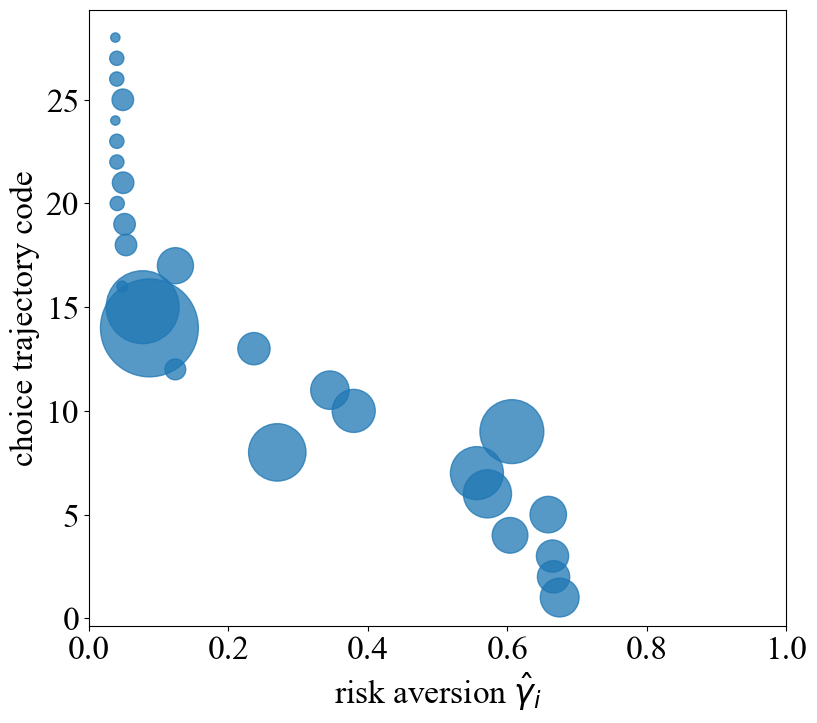

min riskCoef: 0.037914888827584425
max riskCoef: 0.674969473660405
PearsonRResult(statistic=np.float64(-0.8690530470893447), pvalue=np.float64(0.0))


In [154]:
model = pickle.load(open('models_psm_rpm/diverse_gen_3type_rpm_class_3.pkl', 'rb'))
plot_coef_code(df_diverse_3type_edited, model)

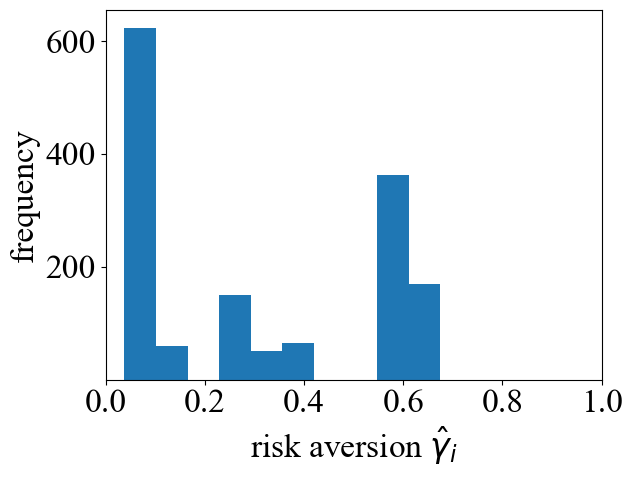

In [288]:
plt.hist(df_diverse_3type_edited['riskCoef'])
plt.ylabel('frequency')
plt.xlabel(r'risk aversion $\hat{\gamma}_i$')
plt.xticks(np.arange(0,1.1,0.2))
plt.yticks([200,400,600])
plt.show()

In [9]:
# Choices are generated by a RPM model with trembling hands
trembling_prob = 0.05

df_rpm_trembling = df_const_risk_encode[['path_code'] + x_cols + choice_cols] 

model_rpm_trembling = DCM.mixedDiscrete(data=df_rpm_trembling,
                choice = choice_cols,
                x1 = 300,
                x2 = x_cols,
                p1 = 0.5,
                func = 'rpmLogitProb')


# create datasets
like_cols = [f'layer_like_{i}' for i in range(1, 6)]
df_rpm_trembling[like_cols] = model_rpm_trembling.choiceProb(
                        params={'riskCoef':0.3,'temp':1.7,'delta':1})

df_rpm_trembling[like_cols] = df_rpm_trembling[like_cols].apply(lambda x: 
                        x*(1-trembling_prob) + (1-x)*trembling_prob)

df_rpm_trembling = generate_choices_from_prob(df_rpm_trembling, base_count=1000)[x_cols + choice_cols + ['path_code','choice_like']]
df_rpm_trembling = df_rpm_trembling.reset_index().rename(columns={'index':'pid'})

# remove the outliers (4 obs.)
pid_outlier = df_rpm_trembling.loc[df_rpm_trembling[x_cols].ge(300).any(axis=1), 'pid']
df_rpm_trembling = df_rpm_trembling[~df_rpm_trembling['pid'].isin(pid_outlier)]
print('outliers removed:', len(pid_outlier))

outliers removed: 4


f:\OneDrive - University of Warwick\preference_reanalysis\staircase\utils.py:168: RuntimeWarning: divide by zero encountered in divide
  return - np.log(p1/p2)/np.log(x1/x2)


In [10]:
model = DCM.mixedDiscrete(data=df_rpm_trembling,
                choice = choice_cols,
                x1 = 300,
                x2 = x_cols,
                p1 = 0.5,
                func='rpmLogitProb')

model.set_init_param(param_keys=['riskCoef','temp'],param_init=[0.5,1.0])
model.fit_param(bounds=bounds)
pred_const_model_risk = model.predict()
pred_const_model_risk['approx_log_like'] = model.result.fun / 1000

  message: CONVERGENCE: RELATIVE REDUCTION OF F <= FACTR*EPSMCH
  success: True
   status: 0
      fun: 3174537.40465831
        x: [ 2.737e-01  1.957e+00]
      nit: 8
      jac: [-1.863e-01 -2.328e-01]
     nfev: 27
     njev: 9
 hess_inv: <2x2 LbfgsInvHessProduct with dtype=float64>


In [12]:
bounds = [(0,1)]

model = DCM.mixedDiscrete(data=df_rpm_trembling,
                choice = choice_cols,
                x1 = 300,
                x2 = x_cols,
                p1 = 0.5,
                fixed_args= {'temp':2.0},
                func = 'rpmLogitProb')


model.set_init_param(param_keys=['riskCoef'],param_init=[0.3])
model.fit_param(bounds=bounds)

  message: CONVERGENCE: RELATIVE REDUCTION OF F <= FACTR*EPSMCH
  success: True
   status: 0
      fun: 3174580.995178323
        x: [ 2.568e-01]
      nit: 2
      jac: [-4.657e-02]
     nfev: 8
     njev: 4
 hess_inv: <1x1 LbfgsInvHessProduct with dtype=float64>


In [13]:
DCM.bisection_search(model, bounds, arg_name = 'temp', arg_range = [0.2, 2.0],
                     n_class=2, n_init_point = 8, name_prefix = 'models_psm_rpm/trembling_gen_rpm')

Searching optimal value for temp
Step 1: 0.7999999999999999
Evaluation metrics: 3732.942604914537, 3800.9761708055444
Step 2: 0.6
Evaluation metrics: 3740.664867670622, 3756.645112128106
Step 3: 0.7333333333333334
Evaluation metrics: 3831.802398218086, 3729.5842530982914
Step 4: 0.6444444444444444
Evaluation metrics: 3733.2533443520497, 3734.8105521348116
Step 5: 0.7037037037037037
Evaluation metrics: 3744.2989396701196, 3729.530430217898
Step 6: 0.7432098765432098
Evaluation metrics: 3731.346905693464, 3729.8256852834784
Step 7: 0.716872427983539
Evaluation metrics: 3729.422272871347, 3730.9359647119236
Step 8: 0.7344307270233196
Evaluation metrics: 3729.616698914364, 3729.6060094104896
Step 9: 0.7227251943301325
Evaluation metrics: 3729.4439013661404, 3729.916759013641
Step 10: 0.7149215058680078
Evaluation metrics: 3729.424548981567, 3729.5349309715257


({'temp': 0.7149215058680078}, np.float64(3729.4246923439637))

In [14]:
DCM.bisection_search(model, bounds, arg_name = 'temp', arg_range = [0.2, 2.0],
                     n_class=3, n_init_point = 8, name_prefix = 'models_psm_rpm/trembling_gen_rpm')

Searching optimal value for temp
Step 1: 0.7999999999999999
Evaluation metrics: 3956.249247107583, 4135.174276104613
Step 2: 0.6
Evaluation metrics: 3914.041466694532, 4024.5185248140824
Step 3: 0.7333333333333334
Evaluation metrics: 4005.015285318864, 3965.4447015350042
Step 4: 0.6444444444444444
Evaluation metrics: 3941.2827533741975, 3983.100803077393
Step 5: 0.5851851851851853
Evaluation metrics: 3960.18895796148, 3963.6624231331493
Step 6: 0.6246913580246913
Evaluation metrics: 3972.124185768324, 3865.1197131653803
Step 7: 0.6510288065843621
Evaluation metrics: 3958.1752581586443, 3893.901379362832
Step 8: 0.6334705075445817
Evaluation metrics: 3958.812214823568, 4156.0750801369095
Step 9: 0.6451760402377686
Evaluation metrics: 3903.4776270900393, 3891.530904918713
Step 10: 0.637372351775644
Evaluation metrics: 3952.9567046145457, 3958.348040712434


({'temp': 0.637372351775644}, np.float64(3960.2941452344794))

In [15]:
DCM.bisection_search(model, bounds, arg_name = 'temp', arg_range = [0.2, 2.0],
                     n_class=4, n_init_point = 8, name_prefix = 'models_psm_rpm/trembling_gen_rpm')

Searching optimal value for temp
Step 1: 0.7999999999999999
Evaluation metrics: 4338.565822198541, 4363.703635395011
Step 2: 0.6
Evaluation metrics: 4317.844581069001, 4363.153577425681
Step 3: 0.4666666666666667
Evaluation metrics: 4187.043028861744, 4338.396615244492
Step 4: 0.5555555555555556
Evaluation metrics: 4334.307769241951, 4099.060431695779
Step 5: 0.6148148148148149
Evaluation metrics: 4366.808618455965, 4347.231487819259
Step 6: 0.654320987654321
Evaluation metrics: 4101.076929742603, 4093.0624901342408
Step 7: 0.6806584362139918
Evaluation metrics: 4386.867929813669, 4303.093014924294
Step 8: 0.6631001371742113
Evaluation metrics: 4246.992769899392, 4308.000511197193
Step 9: 0.6513946044810244
Evaluation metrics: 4353.884640491939, 4373.12284387459
Step 10: 0.6435909160188997
Evaluation metrics: 4059.0457301619936, 4336.506233174483


({'temp': 0.6435909160188997}, np.float64(4333.340798462705))

In [16]:
print('const params:',pred_const_model_risk)
for i in range(2,5):
    model = pickle.load(open(f'models_psm_rpm/trembling_gen_rpm_class_{i}.pkl', 'rb'))
    pred_metric = model.predict()
    pred_metric['approx_log_like'] = model.eval()
    print(f'model {i}:', pred_metric)

const params: {'accuracy': np.float64(0.6126888217522659), 'RMSE': np.float64(0.2257117406456341), 'cross-entropy': np.float64(0.639383163073174), 'approx_log_like': np.float64(3174.53740465831)}
model 2: {'accuracy': np.float64(0.7323262839879154), 'RMSE': np.float64(0.19907630044897268), 'cross-entropy': np.float64(0.5962604921891792), 'approx_log_like': np.float64(3729.4246923439637)}
model 3: {'accuracy': np.float64(0.7323262839879154), 'RMSE': np.float64(0.19637367056536464), 'cross-entropy': np.float64(0.596049627594107), 'approx_log_like': np.float64(3960.2941452344794)}
model 4: {'accuracy': np.float64(0.7323262839879154), 'RMSE': np.float64(0.196596081664138), 'cross-entropy': np.float64(0.5960022308122837), 'approx_log_like': np.float64(4333.340798462705)}


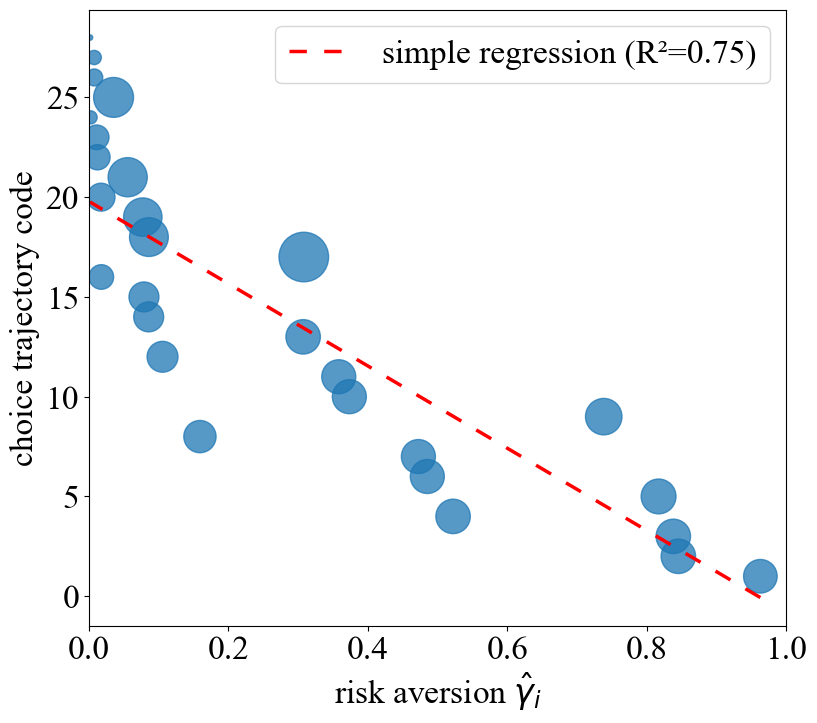

min riskCoef: 0.0016211168187679759
max riskCoef: 0.9626803260023136
PearsonRResult(statistic=np.float64(-0.8674254305089315), pvalue=np.float64(1.1104502997856726e-302))


In [19]:
plt.rcParams['font.family'] = 'Times New Roman'
plt.rcParams['font.size'] = 24
plt.figure(figsize=(9, 8))

model = pickle.load(open('models_psm_rpm/trembling_gen_rpm_class_4.pkl', 'rb'))
df_rpm_trembling['riskCoef'] = 1 - (model.post_prob * model.latent_class['riskCoef']).sum(axis=1)

df_scatter_risk = df_rpm_trembling.groupby(['riskCoef','path_code']).count()['pid'].reset_index()

plt.scatter(df_scatter_risk['riskCoef'],df_scatter_risk['path_code'],
            s=df_scatter_risk['pid']*15, marker='o', alpha=.75)

plt.xlabel(r'risk aversion $\hat{\gamma}_i$')
plt.ylabel('choice trajectory code')
plt.xlim((0,1.0))

slope, intercept, r, p_value, std_err = st.linregress(x=df_rpm_trembling['riskCoef'], y=df_rpm_trembling['path_code'])
pred_subgroup = slope * df_rpm_trembling['riskCoef'] + intercept
plt.plot(df_rpm_trembling['riskCoef'], pred_subgroup, color='red', linestyle=(0,(5,5)), linewidth = 2.5, 
         label= f"simple regression (R²={r**2:.2f})")

plt.legend(loc='best')
plt.show()

print('min riskCoef:',df_rpm_trembling['riskCoef'].min())
print('max riskCoef:',df_rpm_trembling['riskCoef'].max())
print(st.pearsonr(df_rpm_trembling['riskCoef'],df_rpm_trembling['path_code']))

In [20]:
bounds = [(0,None),(0,None)]
model = DCM.mixedDiscrete(data=df_rpm_trembling,
                choice = choice_cols,
                x1 = 300,
                x2 = x_cols,
                p1 = 0.5)

model.set_init_param(param_keys=['riskCoef','temp'],param_init=[0.5,1.0])
model.fit_param(bounds=bounds)
pred_const_model_risk = model.predict()
pred_const_model_risk['approx_log_like'] = model.result.fun / 1000

  message: CONVERGENCE: RELATIVE REDUCTION OF F <= FACTR*EPSMCH
  success: True
   status: 0
      fun: 3228669.1689594937
        x: [ 4.209e-01  4.673e+00]
      nit: 19
      jac: [ 2.794e-01  0.000e+00]
     nfev: 60
     njev: 20
 hess_inv: <2x2 LbfgsInvHessProduct with dtype=float64>


In [21]:
bounds = [(0,1)]

model = DCM.mixedDiscrete(data=df_rpm_trembling,
                choice = choice_cols,
                x1 = 300,
                x2 = x_cols,
                p1 = 0.5,
                fixed_args= {'temp':4.6})


model.set_init_param(param_keys=['riskCoef'],param_init=[0.5])
model.fit_param(bounds=bounds)

  message: CONVERGENCE: RELATIVE REDUCTION OF F <= FACTR*EPSMCH
  success: True
   status: 0
      fun: 3228677.486484928
        x: [ 4.181e-01]
      nit: 7
      jac: [-5.122e-01]
     nfev: 18
     njev: 9
 hess_inv: <1x1 LbfgsInvHessProduct with dtype=float64>


In [22]:
DCM.bisection_search(model, bounds, arg_name = 'temp', arg_range = [0.2, 4.6],
                     n_class=2, n_init_point = 8, name_prefix = 'models_psm_rpm/trembling_gen_rum')

Searching optimal value for temp
Step 1: 1.6666666666666665
Evaluation metrics: 3628.1863808649236, 3921.637187452129
Step 2: 2.155555555555555
Evaluation metrics: 3945.0287591586257, 3288.1920999665253
Step 3: 1.8296296296296293
Evaluation metrics: 3816.0729056358477, 3930.9500744246698
Step 4: 2.046913580246913
Evaluation metrics: 3559.4399829486556, 3407.088160255759
Step 5: 2.1917695473251024
Evaluation metrics: 3430.8328771911815, 3287.33833026099
Step 6: 2.2883401920438953
Evaluation metrics: 3295.096589009955, 3294.923472328874
Step 7: 2.2239597622313667
Evaluation metrics: 3293.7178458647336, 3439.041984325151
Step 8: 2.2668800487730527
Evaluation metrics: 3293.0602218254935, 3288.471500502353
Step 9: 2.295493573134176
Evaluation metrics: 3293.48092270718, 3288.7741436383153
Step 10: 2.27641789022676
Evaluation metrics: 3292.5646086041224, 3817.4437099493034


({'temp': 2.27641789022676}, np.float64(3288.444361811917))

In [23]:
DCM.bisection_search(model, bounds, arg_name = 'temp', arg_range = [0.2, 4.6],
                     n_class=3, n_init_point = 8, name_prefix = 'models_psm_rpm/trembling_gen_rum')

Searching optimal value for temp
Step 1: 1.6666666666666665
Evaluation metrics: 3751.425176744794, 4324.900945419581
Step 2: 2.155555555555555
Evaluation metrics: 4368.171779670017, 3679.134035227332
Step 3: 1.8296296296296293
Evaluation metrics: 3560.758705065306, 3916.4968711880965
Step 4: 2.046913580246913
Evaluation metrics: 4082.9634580761904, 3543.1868013716235
Step 5: 2.1917695473251024
Evaluation metrics: 4056.385490621173, 3872.0974876365394
Step 6: 2.2883401920438953
Evaluation metrics: 4046.1569220049882, 3974.074453835985
Step 7: 2.352720621856424
Evaluation metrics: 3667.272831348841, 3318.5803329797614
Step 8: 2.309800335314738
Evaluation metrics: 3317.5551079036027, 3320.0499101024675
Step 9: 2.2811868109536144
Evaluation metrics: 3568.6301728285334, 3635.57344292691
Step 10: 2.3002624938610303
Evaluation metrics: 3670.9261534806747, 3300.7715303803625


({'temp': 2.3002624938610303}, np.float64(3826.146422658741))

In [24]:
DCM.bisection_search(model, bounds, arg_name = 'temp', arg_range = [0.2, 4.6],
                     n_class=4, n_init_point = 8, name_prefix = 'models_psm_rpm/trembling_gen_rum')

Searching optimal value for temp
Step 1: 1.6666666666666665
Evaluation metrics: 4579.252899589024, 4610.708937171911
Step 2: 2.155555555555555
Evaluation metrics: 4646.503006574979, 4150.4871012340145
Step 3: 1.8296296296296293
Evaluation metrics: 3552.9172883439087, 3613.1297125352494
Step 4: 2.046913580246913
Evaluation metrics: 4355.9149786845555, 3950.1089710590945
Step 5: 1.902057613168724
Evaluation metrics: 3631.7050639192526, 3671.129449161303
Step 6: 1.9986282578875167
Evaluation metrics: 4427.594906574118, 4183.375193233694
Step 7: 2.0630086877000453
Evaluation metrics: 3906.0270101106826, 3769.579673647731
Step 8: 2.1059289742417313
Evaluation metrics: 4291.127706644997, 3953.337922762627
Step 9: 2.077315449880607
Evaluation metrics: 3752.3498873275466, 4157.51618861011
Step 10: 2.096391132788023
Evaluation metrics: 4110.01282026822, 3741.448075418294


({'temp': 2.096391132788023}, np.float64(3944.774392968241))

In [25]:
print('const params:',pred_const_model_risk)
for i in range(2,5):
    model = pickle.load(open(f'models_psm_rpm/trembling_gen_rum_class_{i}.pkl', 'rb'))
    pred_metric = model.predict()
    pred_metric['approx_log_like'] = model.eval()
    print(f'model {i}:', pred_metric)

const params: {'accuracy': np.float64(0.6114803625377644), 'RMSE': np.float64(0.2294972469349612), 'cross-entropy': np.float64(0.6502858346343391), 'approx_log_like': np.float64(3228.6691689594936)}
model 2: {'accuracy': np.float64(0.6122860020140988), 'RMSE': np.float64(0.23216539731890823), 'cross-entropy': np.float64(0.6565915814867809), 'approx_log_like': np.float64(3288.444361811917)}
model 3: {'accuracy': np.float64(0.6126888217522659), 'RMSE': np.float64(0.23027706509994167), 'cross-entropy': np.float64(0.6521658275222668), 'approx_log_like': np.float64(3826.146422658741)}
model 4: {'accuracy': np.float64(0.6122860020140988), 'RMSE': np.float64(0.23098630609250007), 'cross-entropy': np.float64(0.6536870447287368), 'approx_log_like': np.float64(3944.774392968241)}


C:\Users\zarkwang\AppData\Local\Temp\ipykernel_19660\3304625460.py:22: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend(loc='best')


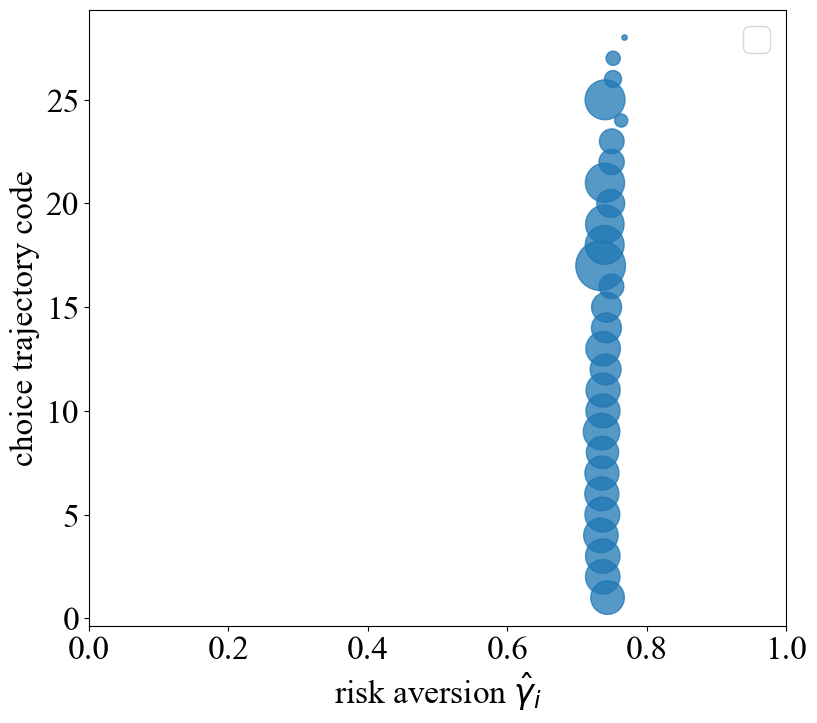

min riskCoef: 0.7336435785619202
max riskCoef: 0.7679393748033849
PearsonRResult(statistic=np.float64(0.4901620216872041), pvalue=np.float64(3.818768691954624e-61))


In [26]:
plt.rcParams['font.family'] = 'Times New Roman'
plt.rcParams['font.size'] = 24
plt.figure(figsize=(9, 8))

model = pickle.load(open('models_psm_rpm/trembling_gen_rum_class_3.pkl', 'rb'))
df_rpm_trembling['riskCoef'] = 1 - (model.post_prob * model.latent_class['riskCoef']).sum(axis=1)

df_scatter_risk = df_rpm_trembling.groupby(['riskCoef','path_code']).count()['pid'].reset_index()

plt.scatter(df_scatter_risk['riskCoef'],df_scatter_risk['path_code'],
            s=df_scatter_risk['pid']*15, marker='o', alpha=.75)

plt.xlabel(r'risk aversion $\hat{\gamma}_i$')
plt.ylabel('choice trajectory code')
plt.xlim((0,1.0))

# slope, intercept, r, p_value, std_err = st.linregress(x=df_rpm_trembling['riskCoef'], y=df_rpm_trembling['path_code'])
# pred_subgroup = slope * df_rpm_trembling['riskCoef'] + intercept
# plt.plot(df_rpm_trembling['riskCoef'], pred_subgroup, color='red', linestyle=(0,(5,5)), linewidth = 2.5, 
#          label= f"simple regression (R²={r**2:.2f})")

plt.legend(loc='best')
plt.show()

print('min riskCoef:',df_rpm_trembling['riskCoef'].min())
print('max riskCoef:',df_rpm_trembling['riskCoef'].max())
print(st.pearsonr(df_rpm_trembling['riskCoef'],df_rpm_trembling['path_code']))

In [159]:
# trembling prob. = 0.05, riskCoef = 0.7
# trembing hand is the main source of noise in decision-making (so temp is set to a very low value)
trembling_prob = 0.05

df_diverse_trembling = df_const_risk_encode[['path_code'] + x_cols + choice_cols] 

model_rpm_trembling = DCM.mixedDiscrete(data=df_diverse_trembling,
                choice = choice_cols,
                x1 = 300,
                x2 = x_cols,
                p1 = 0.5,
                func = 'rpmLogitProb')


# create datasets
def gen_trembling(risk_coefs,base_count):

    _diverse = pd.DataFrame()

    like_cols = [f'layer_like_{i}' for i in range(1, 6)]

    for risk_coef in risk_coefs:
        df_diverse_trembling[like_cols] = model_rpm_trembling.choiceProb(
            params={'riskCoef': risk_coef, 'temp': 0.01, 'delta': 1})

        df_diverse_trembling[like_cols] = df_diverse_trembling[like_cols].apply(lambda x: 
                            x*(1-trembling_prob) + (1-x)*trembling_prob)
        
        var_list = x_cols + choice_cols + ['path_code','choice_like']
        
        _tmp_choice = generate_choices_from_prob(df_diverse_trembling, base_count)[var_list]

        _diverse = pd.concat([_diverse, _tmp_choice], ignore_index=True)

    result_df = _diverse.reset_index().rename(columns={'index':'pid'})

    return result_df


df_trembling_2type = gen_trembling(risk_coefs=[0.3,0.7],base_count=500)
df_trembling_3type = gen_trembling(risk_coefs=[0.3,0.5,0.7],base_count=500)

pid_outlier = df_trembling_2type.loc[df_trembling_2type[x_cols].ge(300).any(axis=1), :].index
df_trembling_2type_edited = df_trembling_2type[~df_trembling_2type.index.isin(pid_outlier)]
print('outliers removed for two-type sample:',len(df_trembling_2type) - len(df_trembling_2type_edited))

pid_outlier = df_trembling_3type.loc[df_trembling_3type[x_cols].ge(300).any(axis=1), :].index
df_trembling_3type_edited = df_trembling_3type[~df_trembling_3type.index.isin(pid_outlier)]
print('outliers removed for three-type sample:',len(df_trembling_3type) - len(df_trembling_3type_edited))

outliers removed for two-type sample: 0
outliers removed for three-type sample: 0


f:\OneDrive - University of Warwick\preference_reanalysis\staircase\utils.py:168: RuntimeWarning: divide by zero encountered in divide
  return - np.log(p1/p2)/np.log(x1/x2)
f:\OneDrive - University of Warwick\preference_reanalysis\staircase\utils.py:194: RuntimeWarning: overflow encountered in exp
  prob = 1/(1 + np.exp(- param_diff / params['temp']))
f:\OneDrive - University of Warwick\preference_reanalysis\staircase\utils.py:168: RuntimeWarning: divide by zero encountered in divide
  return - np.log(p1/p2)/np.log(x1/x2)
f:\OneDrive - University of Warwick\preference_reanalysis\staircase\utils.py:194: RuntimeWarning: overflow encountered in exp
  prob = 1/(1 + np.exp(- param_diff / params['temp']))
f:\OneDrive - University of Warwick\preference_reanalysis\staircase\utils.py:168: RuntimeWarning: divide by zero encountered in divide
  return - np.log(p1/p2)/np.log(x1/x2)
f:\OneDrive - University of Warwick\preference_reanalysis\staircase\utils.py:194: RuntimeWarning: overflow encounter

In [165]:
tab_count = df_trembling_3type['path_code'].value_counts()
tab_count.index = tab_count.index.astype(int).astype(str)

prop_test = DCM.proportionTest(tab_count)
prop_test.run(hide=True)
prop_test.get_power(method='fisher')
prop_test.get_power(method='barnard')

print('Fisher p-value:',prop_test.get_overall_pvalue(method='fisher')) 
print('Barnard p-value:',prop_test.get_overall_pvalue(method='barnard')) 

Fisher p-value: 2.2217491022585094e-13
Barnard p-value: 1.472575456831476e-10


In [166]:
model = DCM.mixedDiscrete(data=df_trembling_2type,
                choice = choice_cols,
                x1 = 300,
                x2 = x_cols,
                p1 = 0.5,
                func='rpmLogitProb')

model.set_init_param(param_keys=['riskCoef','temp'],param_init=[0.5,0.2])
model.fit_param(bounds=bounds)
pred_const_model_risk = model.predict()
pred_const_model_risk['approx_log_like'] = model.result.fun / 1000

  message: CONVERGENCE: RELATIVE REDUCTION OF F <= FACTR*EPSMCH
  success: True
   status: 0
      fun: 2915156.0759538733
        x: [ 4.863e-01  3.252e-01]
      nit: 9
      jac: [-1.211e+00  2.282e+00]
     nfev: 33
     njev: 11
 hess_inv: <2x2 LbfgsInvHessProduct with dtype=float64>


In [227]:
bounds = [(0,1)]

model = DCM.mixedDiscrete(data=df_trembling_2type,
                choice = choice_cols,
                x1 = 300,
                x2 = x_cols,
                p1 = 0.5,
                fixed_args= {'temp':0.4},
                func = 'rpmLogitProb')


model.set_init_param(param_keys=['riskCoef'],param_init=[0.2])
model.fit_param(bounds=bounds)

  message: CONVERGENCE: NORM OF PROJECTED GRADIENT <= PGTOL
  success: True
   status: 0
      fun: 2926716.094986884
        x: [ 4.634e-01]
      nit: 4
      jac: [ 0.000e+00]
     nfev: 12
     njev: 6
 hess_inv: <1x1 LbfgsInvHessProduct with dtype=float64>


In [172]:
DCM.bisection_search(model, bounds, arg_name = 'temp', arg_range = [0.0, 0.4],
                     n_class=2, n_init_point = 8, name_prefix = 'models_psm_rpm/diverse_trembling_gen_rpm')

Searching optimal value for temp
Step 1: 0.13333333333333336
Evaluation metrics: 2792.3350352207963, 3252.8012051116098
Step 2: 0.0888888888888889
Evaluation metrics: 2638.3196902731256, 2965.3802237368063
Step 3: 0.059259259259259275
Evaluation metrics: 2616.240565815446, 2734.929751991886
Step 4: 0.07901234567901237
Evaluation metrics: 2741.1336245326734, 2618.005339471841
Step 5: 0.06584362139917697
Evaluation metrics: 2608.927911285773, 2646.8815698904978
Step 6: 0.07462277091906724
Evaluation metrics: 2621.1712811653756, 2612.2311824877675
Step 7: 0.06877000457247373
Evaluation metrics: 2608.6155385770758, 2620.42478369981
Step 8: 0.06486816034141141
Evaluation metrics: 2609.3962200253627, 2610.4598923784915
Step 9: 0.0674693898287863
Evaluation metrics: 2611.635672357039, 2608.5602110604477
Step 10: 0.06920354282036956
Evaluation metrics: 2608.9701655528524, 2608.699549996917


({'temp': 0.06920354282036956}, np.float64(2608.699264827759))

In [173]:
DCM.bisection_search(model, bounds, arg_name = 'temp', arg_range = [0.0, 0.4],
                     n_class=3, n_init_point = 8, name_prefix = 'models_psm_rpm/diverse_trembling_gen_rpm')

Searching optimal value for temp
Step 1: 0.13333333333333336
Evaluation metrics: 2940.546859724798, 3559.215514613388
Step 2: 0.0888888888888889
Evaluation metrics: 2691.8890720491754, 3161.1074017668643
Step 3: 0.059259259259259275
Evaluation metrics: 2616.3256821256364, 2943.9022320319123
Step 4: 0.03950617283950618
Evaluation metrics: 2738.8074747355977, 2852.6336066956883
Step 5: 0.05267489711934157
Evaluation metrics: 2948.4445790692616, 2670.445736388294
Step 6: 0.06145404663923183
Evaluation metrics: 2714.0782895084367, 2633.8258523233294
Step 7: 0.055601280292638326
Evaluation metrics: 2644.795555102776, 2878.060968697092
Step 8: 0.05950312452370067
Evaluation metrics: 2676.689252425966, 2615.8554144298205
Step 9: 0.05690189503632577
Evaluation metrics: 2674.7362150376184, 2712.1856274253705
Step 10: 0.05863604802790903
Evaluation metrics: 2649.5720158647887, 2617.5958138438846


({'temp': 0.05863604802790903}, np.float64(2645.241089594348))

In [228]:
DCM.bisection_search(model, bounds, arg_name = 'temp', arg_range = [0.0, 0.4],
                     n_class=4, n_init_point = 8, name_prefix = 'models_psm_rpm/diverse_trembling_gen_rpm')

Searching optimal value for temp
Step 1: 0.13333333333333336
Evaluation metrics: 3231.940042252382, 3784.280740800846
Step 2: 0.0888888888888889
Evaluation metrics: 2895.082173054028, 3460.1977707283113
Step 3: 0.059259259259259275
Evaluation metrics: 2832.228673362241, 3198.0187613598846
Step 4: 0.03950617283950618
Evaluation metrics: 2761.2565180787497, 2942.9107414055193
Step 5: 0.02633744855967079
Evaluation metrics: 2479.4524537863144, 2761.1970705628964
Step 6: 0.03511659807956105
Evaluation metrics: 3615.3575993224113, 2931.1007367955067
Step 7: 0.040969364426154564
Evaluation metrics: 2903.224953129857, 2821.0566538255207
Step 8: 0.0448712086572169
Evaluation metrics: 2770.7796707974835, 2723.6854432125715
Step 9: 0.042269979169842
Evaluation metrics: 2742.1706954609685, 2871.503125649391
Step 10: 0.04400413216142526
Evaluation metrics: 2757.931189856222, 2733.630550634686


({'temp': 0.04400413216142526}, np.float64(2737.1039022470513))

In [230]:
print('const params:',pred_const_model_risk)
for i in range(2,5):
    model = pickle.load(open(f'models_psm_rpm/diverse_trembling_gen_rpm_class_{i}.pkl', 'rb'))
    pred_metric = model.predict()
    pred_metric['approx_log_like'] = model.eval()
    print(f'model {i}:', pred_metric)

const params: {'accuracy': np.float64(0.6036108324974926), 'RMSE': np.float64(0.23515872758292433), 'cross-entropy': np.float64(0.662354854117471), 'approx_log_like': np.float64(nan)}
model 2: {'accuracy': np.float64(0.895085255767302), 'RMSE': np.float64(0.10225688458003351), 'cross-entropy': np.float64(0.3742879499703089), 'approx_log_like': np.float64(2608.699264827759)}
model 3: {'accuracy': np.float64(0.895085255767302), 'RMSE': np.float64(0.09686345077498207), 'cross-entropy': np.float64(0.374407335062484), 'approx_log_like': np.float64(2645.241089594348)}
model 4: {'accuracy': np.float64(0.8992978936810432), 'RMSE': np.float64(0.08484539835872376), 'cross-entropy': np.float64(0.36966150437783935), 'approx_log_like': np.float64(2737.1039022470513)}


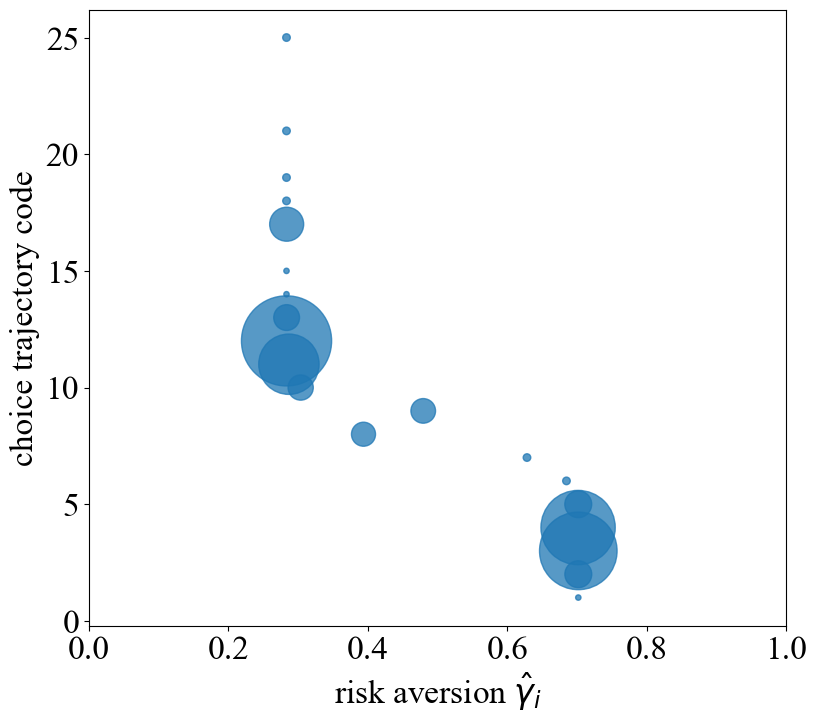

min riskCoef: 0.28329229945898526
max riskCoef: 0.7016532239246545
PearsonRResult(statistic=np.float64(-0.9458184737295952), pvalue=np.float64(0.0))


In [291]:
model = pickle.load(open('models_psm_rpm/diverse_trembling_gen_rpm_class_4.pkl', 'rb'))
plot_coef_code(df_trembling_2type, model)

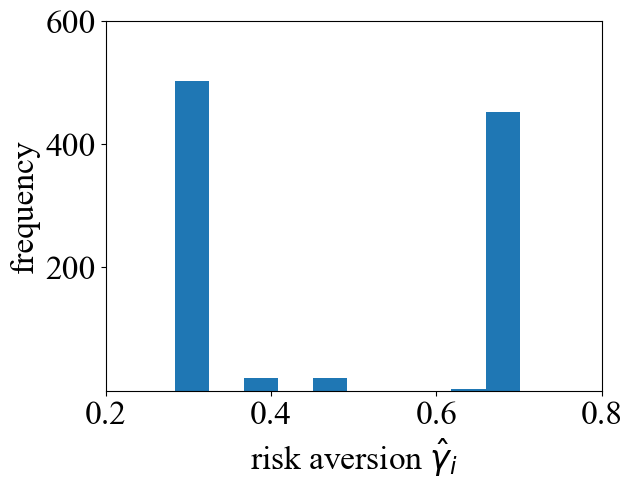

In [292]:
plt.hist(df_trembling_2type['riskCoef'])
plt.ylabel('frequency')
plt.xlabel(r'risk aversion $\hat{\gamma}_i$')
plt.xticks(np.arange(0.2,0.9,0.2))
plt.yticks([200,400,600])
plt.show()

In [192]:
model = DCM.mixedDiscrete(data=df_trembling_2type,
                choice = choice_cols,
                x1 = 300,
                x2 = x_cols,
                p1 = 0.5
                )

model.set_init_param(param_keys=['riskCoef','temp'],param_init=[0.1,1.0])
model.fit_param(bounds=bounds)
pred_const_model_risk = model.predict()
pred_const_model_risk['approx_log_like'] = model.result.fun / 1000

  message: ABNORMAL: 
  success: False
   status: 2
      fun: nan
        x: [ 1.000e-01  1.000e+00]
      nit: 0
      jac: [-5.590e+05 -1.137e+05]
     nfev: 6
     njev: 2
 hess_inv: <2x2 LbfgsInvHessProduct with dtype=float64>


In [211]:
bounds = [(0,1)]

model = DCM.mixedDiscrete(data=df_trembling_2type,
                choice = choice_cols,
                x1 = 300,
                x2 = x_cols,
                p1 = 0.5,
                fixed_args= {'temp':1.0}
                )


model.set_init_param(param_keys=['riskCoef'],param_init=[0.4])
model.fit_param(bounds=bounds)

  message: CONVERGENCE: RELATIVE REDUCTION OF F <= FACTR*EPSMCH
  success: True
   status: 0
      fun: 3190612.6756760078
        x: [ 3.088e-01]
      nit: 7
      jac: [-7.451e-01]
     nfev: 20
     njev: 10
 hess_inv: <1x1 LbfgsInvHessProduct with dtype=float64>


In [212]:
DCM.bisection_search(model, bounds, arg_name = 'temp', arg_range = [0.0, 1.0],
                     n_class=2, n_init_point = 8, name_prefix = 'models_psm_rpm/diverse_trembling_gen_rum')

Searching optimal value for temp
Step 1: 0.6666666666666666
Evaluation metrics: 4643.092037027397, 3945.652714698471
Step 2: 0.5555555555555556
Evaluation metrics: 3828.7646104411215, 3831.613502284933
Step 3: 0.6296296296296297
Evaluation metrics: 4251.262355692342, 3871.069613544457
Step 4: 0.5802469135802469
Evaluation metrics: 3819.57675927505, 3828.933012848959
Step 5: 0.5473251028806585
Evaluation metrics: 3822.8504815376564, 4128.409156873563
Step 6: 0.5692729766803841
Evaluation metrics: 4197.640724924221, 3834.286503234158
Step 7: 0.5546410608139003
Evaluation metrics: 3819.8811574321735, 4146.628672099725
Step 8: 0.5448864502362445
Evaluation metrics: 3869.288064741787, 4160.188849107735
Step 9: 0.5513895239546817
Evaluation metrics: 4184.113642877666, 3831.5106818258473
Step 10: 0.5470541414757235
Evaluation metrics: 3837.766535827566, 4167.319933950257


({'temp': 0.5470541414757235}, np.float64(3840.3181561012448))

In [213]:
DCM.bisection_search(model, bounds, arg_name = 'temp', arg_range = [0.0, 1.0],
                     n_class=3, n_init_point = 8, name_prefix = 'models_psm_rpm/diverse_trembling_gen_rum')

Searching optimal value for temp
Step 1: 0.6666666666666666
Evaluation metrics: 4047.9833229581154, 3845.4905185262833
Step 2: 0.7777777777777778
Evaluation metrics: 4078.028171767035, 3869.3984406756354
Step 3: 0.8518518518518519
Evaluation metrics: 3917.706813227628, 3829.5473887247
Step 4: 0.8024691358024691
Evaluation metrics: 3852.769736457974, 3894.977762110234
Step 5: 0.8353909465020577
Evaluation metrics: 3966.692022698093, 3839.68575350583
Step 6: 0.8573388203017833
Evaluation metrics: 3860.006542231825, 3812.707320653834
Step 7: 0.871970736168267
Evaluation metrics: 3829.1305684817426, 3802.3371518339773
Step 8: 0.881725346745923
Evaluation metrics: 3837.935584187514, 3795.6839667958247
Step 9: 0.8882284204643601
Evaluation metrics: 3814.0323151813222, 3790.358770086268
Step 10: 0.8925638029433183
Evaluation metrics: 3893.664052236426, 3874.416231938639


({'temp': 0.8925638029433183}, np.float64(3801.2073036975103))

In [226]:
DCM.bisection_search(model, bounds, arg_name = 'temp', arg_range = [0.0, 1.0],
                     n_class=4, n_init_point = 8, name_prefix = 'models_psm_rpm/diverse_trembling_gen_rum')

Searching optimal value for temp
Step 1: 0.6666666666666666
Evaluation metrics: 5350.180668780564, 4792.687443519301
Step 2: 0.7777777777777778
Evaluation metrics: 4861.187543575977, 4758.638596738343
Step 3: 0.8518518518518519
Evaluation metrics: 4778.667681273443, 4745.976180809351
Step 4: 0.9012345679012346
Evaluation metrics: 4753.752752941921, 4740.308348205413
Step 5: 0.9341563786008231
Evaluation metrics: 4743.880753614347, 4737.445986399491
Step 6: 0.9561042524005487
Evaluation metrics: 4739.28151552243, 4735.87421862503
Step 7: 0.9707361682670325
Evaluation metrics: 4736.894268377029, 4734.958414967468
Step 8: 0.9804907788446884
Evaluation metrics: 4735.557763036533, 4734.401949867593
Step 9: 0.9869938525631256
Evaluation metrics: 4734.768269699398, 4734.053737937962
Step 10: 0.9913292350420837
Evaluation metrics: 4734.283897513339, 4733.8313574931335


({'temp': 0.9913292350420837}, np.float64(4733.8313574931335))

In [233]:
print('const params:',pred_const_model_risk)
for i in range(2,5):
    model = pickle.load(open(f'models_psm_rpm/diverse_trembling_gen_rum_class_{i}.pkl', 'rb'))
    pred_metric = model.predict()
    pred_metric['approx_log_like'] = model.eval()
    print(f'model {i}:', pred_metric)

const params: {'accuracy': np.float64(0.6036108324974926), 'RMSE': np.float64(0.23515872758292433), 'cross-entropy': np.float64(0.662354854117471), 'approx_log_like': np.float64(nan)}
model 2: {'accuracy': np.float64(0.6469408224674023), 'RMSE': np.float64(0.21814016596755975), 'cross-entropy': np.float64(0.6208859607992819), 'approx_log_like': np.float64(3840.3181561012448)}
model 3: {'accuracy': np.float64(0.6834503510531595), 'RMSE': np.float64(0.21596694490942153), 'cross-entropy': np.float64(0.6167115308848278), 'approx_log_like': np.float64(3801.2073036975103)}
model 4: {'accuracy': np.float64(0.6036108324974926), 'RMSE': np.float64(0.2396598384120123), 'cross-entropy': np.float64(0.6723562446251963), 'approx_log_like': np.float64(4733.8313574931335)}


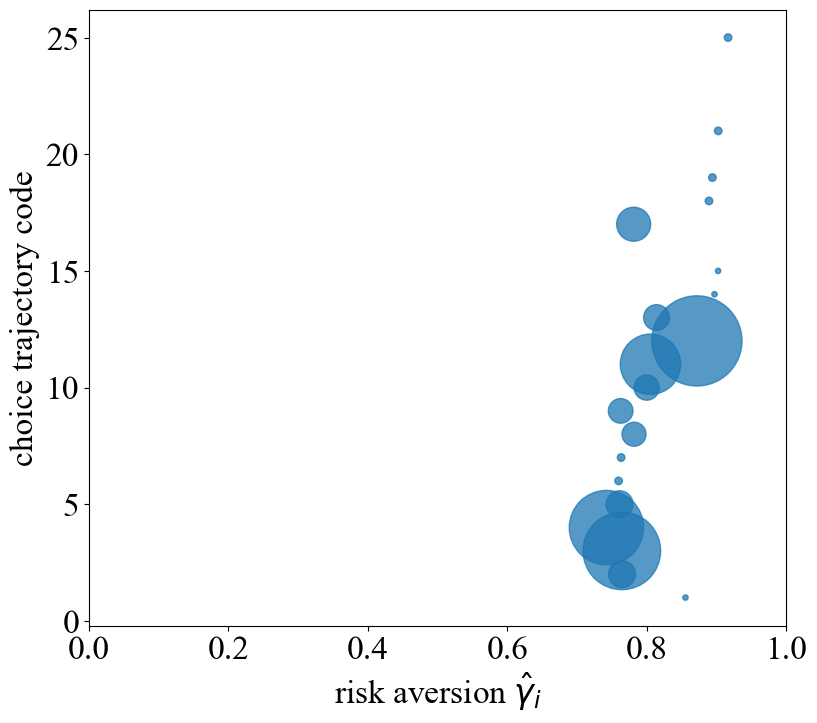

min riskCoef: 0.7419794522848084
max riskCoef: 0.9163692271244606
PearsonRResult(statistic=np.float64(0.773575409976295), pvalue=np.float64(2.4621597314309837e-199))


In [272]:
model = pickle.load(open('models_psm_rpm/diverse_trembling_gen_rum_class_3.pkl', 'rb'))
plot_coef_code(df_trembling_2type, model)

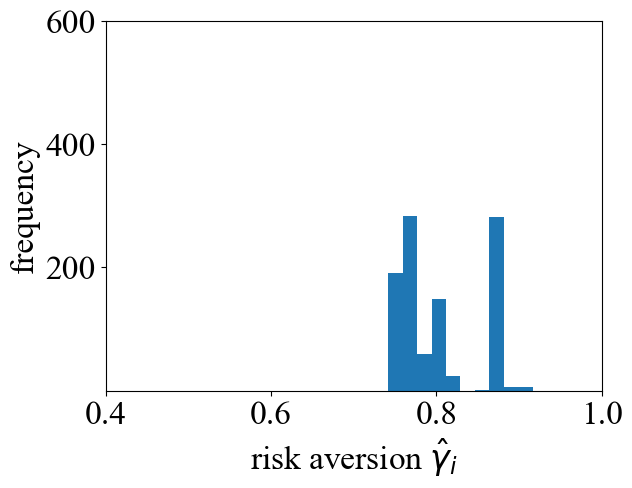

In [280]:
plt.hist(df_trembling_2type['riskCoef'])
plt.ylabel('frequency')
plt.xlabel(r'risk aversion $\hat{\gamma}_i$')
plt.xticks(np.arange(0.4,1.1,0.2))
plt.yticks([200,400,600])
plt.show()

In [238]:
model = DCM.mixedDiscrete(data=df_trembling_3type,
                choice = choice_cols,
                x1 = 300,
                x2 = x_cols,
                p1 = 0.5,
                func='rpmLogitProb')

model.set_init_param(param_keys=['riskCoef','temp'],param_init=[0.5,0.2])
model.fit_param(bounds=bounds)
pred_const_model_risk = model.predict()
pred_const_model_risk['approx_log_like'] = model.result.fun / 1000

  message: CONVERGENCE: RELATIVE REDUCTION OF F <= FACTR*EPSMCH
  success: True
   status: 0
      fun: 4139518.736251528
        x: [ 5.373e-01  2.422e-01]
      nit: 5
      jac: [-1.984e+01 -3.539e+00]
     nfev: 24
     njev: 8
 hess_inv: <2x2 LbfgsInvHessProduct with dtype=float64>


In [243]:
bounds = [(0,1)]

model = DCM.mixedDiscrete(data=df_trembling_3type,
                choice = choice_cols,
                x1 = 300,
                x2 = x_cols,
                p1 = 0.5,
                fixed_args= {'temp':0.3},
                func = 'rpmLogitProb')


model.set_init_param(param_keys=['riskCoef'],param_init=[0.2])
model.fit_param(bounds=bounds)

  message: CONVERGENCE: RELATIVE REDUCTION OF F <= FACTR*EPSMCH
  success: True
   status: 0
      fun: 4164278.7940614754
        x: [ 5.316e-01]
      nit: 4
      jac: [ 2.794e-01]
     nfev: 12
     njev: 6
 hess_inv: <1x1 LbfgsInvHessProduct with dtype=float64>


In [244]:
DCM.bisection_search(model, bounds, arg_name = 'temp', arg_range = [0.0, 0.3],
                     n_class=2, n_init_point = 8, name_prefix = 'models_psm_rpm/diverse_trembling_gen_3type_rpm')

Searching optimal value for temp
Step 1: 0.1
Evaluation metrics: 4320.79952630474, 4618.882472620404
Step 2: 0.13333333333333333
Evaluation metrics: 4463.313268940908, 4384.754318396265
Step 3: 0.1111111111111111
Evaluation metrics: 4330.695158932122, 4460.162624830264
Step 4: 0.0962962962962963
Evaluation metrics: 4321.558193810735, 4363.148349017411
Step 5: 0.10617283950617284
Evaluation metrics: 4337.03495953651, 4324.274894098989
Step 6: 0.09958847736625515
Evaluation metrics: 4320.7694820843735, 4333.470737755036
Step 7: 0.09519890260631003
Evaluation metrics: 4322.252849589948, 4322.4240609650415
Step 8: 0.09812528577960677
Evaluation metrics: 4325.262000776485, 4320.888894844097
Step 9: 0.10007620789513795
Evaluation metrics: 4321.624233745337, 4320.806998374105


({'temp': 0.10007620789513795}, np.float64(4320.807463261332))

In [245]:
DCM.bisection_search(model, bounds, arg_name = 'temp', arg_range = [0.0, 0.3],
                     n_class=3, n_init_point = 8, name_prefix = 'models_psm_rpm/diverse_trembling_gen_3type_rpm')

Searching optimal value for temp
Step 1: 0.1
Evaluation metrics: 4647.819170242332, 4960.586745251064
Step 2: 0.06666666666666668
Evaluation metrics: 4649.923563447617, 4951.85776008787
Step 3: 0.04444444444444445
Evaluation metrics: 4528.303964584029, 4819.1014344092
Step 4: 0.05925925925925927
Evaluation metrics: 4672.616839818098, 4595.750106159389
Step 5: 0.04938271604938272
Evaluation metrics: 4540.835606730319, 4669.272823828018
Step 6: 0.04279835390946503
Evaluation metrics: 4527.936115072335, 4574.511227364535
Step 7: 0.047187928669410156
Evaluation metrics: 4540.8182526157, 4533.472497070998
Step 8: 0.0442615454961134
Evaluation metrics: 4528.15162810613, 4543.564041338712
Step 9: 0.04231062338058224
Evaluation metrics: 4528.29584157233, 4531.06010386504


({'temp': 0.04231062338058224}, np.float64(4528.295107357463))

In [246]:
DCM.bisection_search(model, bounds, arg_name = 'temp', arg_range = [0.0, 0.3],
                     n_class=4, n_init_point = 8, name_prefix = 'models_psm_rpm/diverse_trembling_gen_3type_rpm')

Searching optimal value for temp
Step 1: 0.1
Evaluation metrics: 5041.445905853343, 5508.604768107833
Step 2: 0.06666666666666668
Evaluation metrics: 4887.103922460254, 5174.052088480677
Step 3: 0.04444444444444445
Evaluation metrics: 4218.918800439766, 5026.099559928704
Step 4: 0.029629629629629638
Evaluation metrics: 4063.347107595656, 4898.686850147225
Step 5: 0.039506172839506186
Evaluation metrics: 8484.041340814147, 4147.596735872089
Step 6: 0.03292181069958849
Evaluation metrics: 4078.121792849131, 4244.584743351118
Step 7: 0.02853223593964336
Evaluation metrics: 4062.8450585332766, 4120.142702327827
Step 8: 0.03145861911294011
Evaluation metrics: 5009.282467886691, 4698.0954870943715
Step 9: 0.029507696997408944
Evaluation metrics: 4063.1674943955277, 4081.713397556338


({'temp': 0.029507696997408944}, np.float64(4063.1674934884836))

In [248]:
print('const params:',pred_const_model_risk)
for i in range(2,5):
    model = pickle.load(open(f'models_psm_rpm/diverse_trembling_gen_3type_rpm_class_{i}.pkl', 'rb'))
    pred_metric = model.predict()
    pred_metric['approx_log_like'] = model.eval()
    print(f'model {i}:', pred_metric)

const params: {'accuracy': np.float64(0.6623914495657981), 'RMSE': np.float64(0.1895760374916643), 'cross-entropy': np.float64(0.5530419153308659), 'approx_log_like': np.float64(4139.518736251528)}
model 2: {'accuracy': np.float64(0.8432865731462924), 'RMSE': np.float64(0.12415852294525746), 'cross-entropy': np.float64(0.4140827648128924), 'approx_log_like': np.float64(4320.807463261332)}
model 3: {'accuracy': np.float64(0.9413493653974613), 'RMSE': np.float64(0.08032260697776958), 'cross-entropy': np.float64(0.36353183710964554), 'approx_log_like': np.float64(4528.295107357463)}
model 4: {'accuracy': np.float64(0.9103540414161654), 'RMSE': np.float64(0.07085098337863775), 'cross-entropy': np.float64(0.28295998388143206), 'approx_log_like': np.float64(4063.1674934884836)}


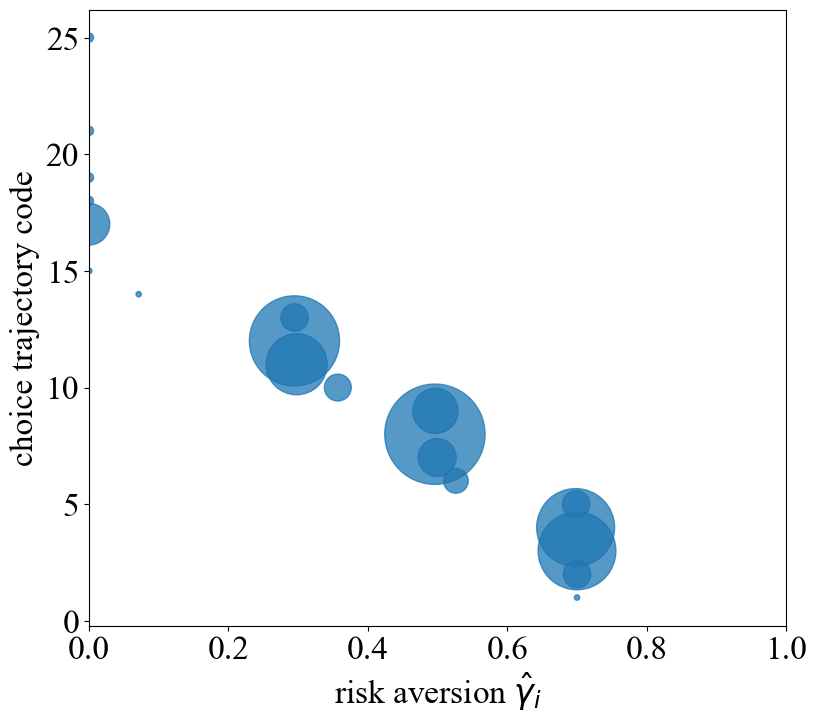

min riskCoef: 3.947174920249097e-09
max riskCoef: 0.6997837888201726
PearsonRResult(statistic=np.float64(-0.9830752100999528), pvalue=np.float64(0.0))


In [295]:
model = pickle.load(open('models_psm_rpm/diverse_trembling_gen_3type_rpm_class_4.pkl', 'rb'))
plot_coef_code(df_trembling_3type, model)

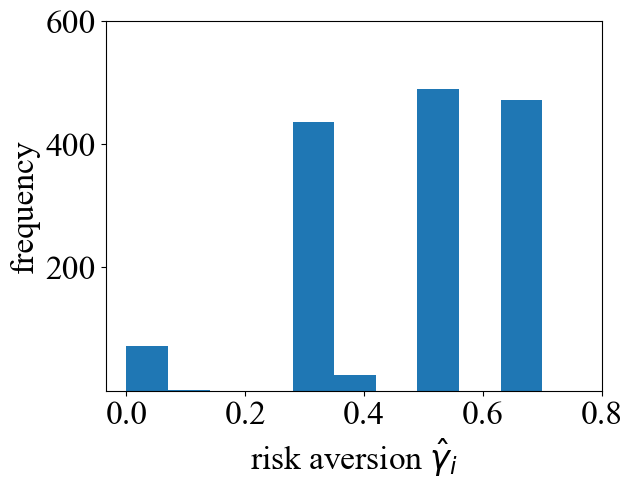

In [296]:
plt.hist(df_trembling_3type['riskCoef'])
plt.ylabel('frequency')
plt.xlabel(r'risk aversion $\hat{\gamma}_i$')
plt.xticks(np.arange(0,0.9,0.2))
plt.yticks([200,400,600])
plt.show()

In [256]:
model = DCM.mixedDiscrete(data=df_trembling_3type,
                choice = choice_cols,
                x1 = 300,
                x2 = x_cols,
                p1 = 0.5
                )

model.set_init_param(param_keys=['riskCoef','temp'],param_init=[0.5,1.0])
model.fit_param(bounds=bounds)
pred_const_model_risk = model.predict()
pred_const_model_risk['approx_log_like'] = model.result.fun / 1000

  message: CONVERGENCE: RELATIVE REDUCTION OF F <= FACTR*EPSMCH
  success: True
   status: 0
      fun: 4611104.285612256
        x: [ 4.029e-01  1.000e+00]
      nit: 8
      jac: [-9.313e-02 -1.029e+06]
     nfev: 33
     njev: 11
 hess_inv: <2x2 LbfgsInvHessProduct with dtype=float64>


In [257]:
bounds = [(0,1)]

model = DCM.mixedDiscrete(data=df_trembling_3type,
                choice = choice_cols,
                x1 = 300,
                x2 = x_cols,
                p1 = 0.5,
                fixed_args= {'temp':1.0},
                func = 'rpmLogitProb')


model.set_init_param(param_keys=['riskCoef'],param_init=[0.2])
model.fit_param(bounds=bounds)

  message: CONVERGENCE: RELATIVE REDUCTION OF F <= FACTR*EPSMCH
  success: True
   status: 0
      fun: 4632259.422669663
        x: [ 3.765e-01]
      nit: 3
      jac: [ 9.313e-02]
     nfev: 10
     njev: 5
 hess_inv: <1x1 LbfgsInvHessProduct with dtype=float64>


In [258]:
DCM.bisection_search(model, bounds, arg_name = 'temp', arg_range = [0.0, 1.0],
                     n_class=2, n_init_point = 8, name_prefix = 'models_psm_rpm/diverse_trembling_gen_3type_rum')

Searching optimal value for temp
Step 1: 0.33333333333333337
Evaluation metrics: 5226.653346189858, 5506.139479766509
Step 2: 0.22222222222222227
Evaluation metrics: 4689.579582783298, 5331.8067040553315
Step 3: 0.1481481481481482
Evaluation metrics: 4433.848654519432, 4846.381354932535
Step 4: 0.09876543209876545
Evaluation metrics: 4320.768759105163, 4610.497572373466
Step 5: 0.13168724279835395
Evaluation metrics: 4472.880963112522, 4379.734731245139
Step 6: 0.1097393689986283
Evaluation metrics: 4328.612958823316, 4453.282268872643
Step 7: 0.09510745313214453
Evaluation metrics: 4322.3209050535625, 4358.982325442397
Step 8: 0.10486206370980036
Evaluation metrics: 4340.121731039328, 4323.050281712837
Step 9: 0.09835898999136314
Evaluation metrics: 4320.8219884488635, 4330.904466196981
Step 10: 0.10269437247032129
Evaluation metrics: 4323.234096991415, 4321.643743183732


({'temp': 0.10269437247032129}, np.float64(4321.606653634966))

In [259]:
DCM.bisection_search(model, bounds, arg_name = 'temp', arg_range = [0.0, 1.0],
                     n_class=3, n_init_point = 8, name_prefix = 'models_psm_rpm/diverse_trembling_gen_3type_rum')

Searching optimal value for temp
Step 1: 0.33333333333333337
Evaluation metrics: 5831.9974921321245, 6113.12623528621
Step 2: 0.22222222222222227
Evaluation metrics: 5007.210164023979, 5937.145446821361
Step 3: 0.1481481481481482
Evaluation metrics: 4766.76482131316, 5654.327248227705
Step 4: 0.09876543209876545
Evaluation metrics: 4660.190321289088, 4954.287850103026
Step 5: 0.06584362139917696
Evaluation metrics: 4643.247600443753, 4956.507104524937
Step 6: 0.04389574759945131
Evaluation metrics: 4527.925798921371, 4812.277559090107
Step 7: 0.058527663465935076
Evaluation metrics: 4682.970148136188, 4590.841275466926
Step 8: 0.04877305288827923
Evaluation metrics: 4538.545943694464, 4662.540635688754
Step 9: 0.042269979169842
Evaluation metrics: 4528.335183745371, 4570.359311530452
Step 10: 0.04660536164880015
Evaluation metrics: 4543.730026037716, 4531.959865467721


({'temp': 0.04660536164880015}, np.float64(4531.962917378372))

In [260]:
DCM.bisection_search(model, bounds, arg_name = 'temp', arg_range = [0.0, 1.0],
                     n_class=4, n_init_point = 8, name_prefix = 'models_psm_rpm/diverse_trembling_gen_3type_rum')

Searching optimal value for temp
Step 1: 0.33333333333333337
Evaluation metrics: 6261.0611429444525, 6543.844327817925
Step 2: 0.22222222222222227
Evaluation metrics: 5719.565013520078, 6369.0987909906
Step 3: 0.1481481481481482
Evaluation metrics: 5022.493991120298, 6113.4016606287605
Step 4: 0.09876543209876545
Evaluation metrics: 5152.668345010497, 5498.910367523698
Step 5: 0.06584362139917696
Evaluation metrics: 4941.3214169425355, 5119.525671084371
Step 6: 0.04389574759945131
Evaluation metrics: 4590.278688373819, 5073.00070490305
Step 7: 0.029263831732967538
Evaluation metrics: 4062.8985299303104, 4828.298325250984
Step 8: 0.03901844231062338
Evaluation metrics: 11021.42899622439, 4141.212032145116
Step 9: 0.04552151602906061
Evaluation metrics: 4876.621099536579, 4771.5525816282825
Step 10: 0.04985689850801876
Evaluation metrics: 4629.583161866775, 4305.184104602059


({'temp': 0.04985689850801876}, np.float64(4725.999297952813))

In [261]:
print('const params:',pred_const_model_risk)
for i in range(2,5):
    model = pickle.load(open(f'models_psm_rpm/diverse_trembling_gen_3type_rum_class_{i}.pkl', 'rb'))
    pred_metric = model.predict()
    pred_metric['approx_log_like'] = model.eval()
    print(f'model {i}:', pred_metric)

const params: {'accuracy': np.float64(0.6233800935203739), 'RMSE': np.float64(0.21854827599905352), 'cross-entropy': np.float64(0.616045996741784), 'approx_log_like': np.float64(4611.104285612257)}
model 2: {'accuracy': np.float64(0.8432865731462924), 'RMSE': np.float64(0.12447578918000626), 'cross-entropy': np.float64(0.4140451611266165), 'approx_log_like': np.float64(4321.606653634966)}
model 3: {'accuracy': np.float64(0.9413493653974613), 'RMSE': np.float64(0.08307148467589709), 'cross-entropy': np.float64(0.36040954901088773), 'approx_log_like': np.float64(4531.962917378372)}
model 4: {'accuracy': np.float64(0.9413493653974613), 'RMSE': np.float64(0.08517046554978298), 'cross-entropy': np.float64(0.35925279062796356), 'approx_log_like': np.float64(4725.999297952813)}


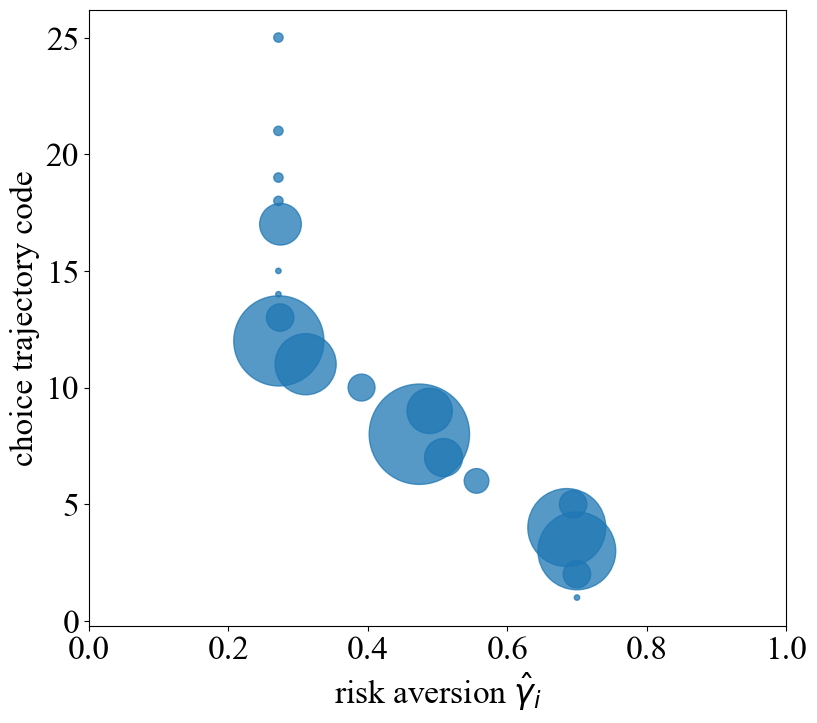

min riskCoef: 0.2716988589258146
max riskCoef: 0.6997688968390229
PearsonRResult(statistic=np.float64(-0.944510620228025), pvalue=np.float64(0.0))


In [262]:
model = pickle.load(open('models_psm_rpm/diverse_trembling_gen_3type_rum_class_4.pkl', 'rb'))
plot_coef_code(df_trembling_3type, model)

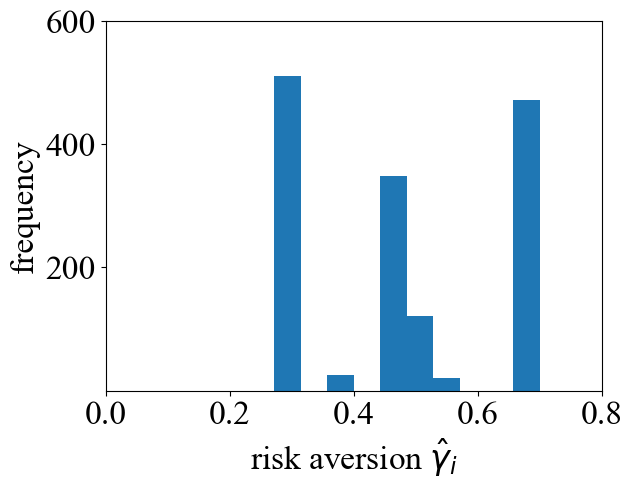

In [294]:
plt.hist(df_trembling_3type['riskCoef'])
plt.ylabel('frequency')
plt.xlabel(r'risk aversion $\hat{\gamma}_i$')
plt.xticks(np.arange(0,0.9,0.2))
plt.yticks([200,400,600])
plt.show()